In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pip install missingno

Note: you may need to restart the kernel to use updated packages.


In [3]:
import missingno as msno

In [4]:
data=pd.read_csv('karnataka.csv')
df=pd.DataFrame(data)
df.head(10)

,Year,Location,Area,Rainfall,Temperature,Soil type,Irrigation,yeilds,Humidity,Crops,price,Season
0,2004,Mangalore,1279,2903.1,27,Alluvial,Drip,2570,57.0,Coconut,200000.0,Kharif
1,2004,Mangalore,13283,2903.1,27,Alluvial,Drip,27170,57.5,Coconut,4847.0,Kharif
2,2004,Mangalore,52119,2903.1,27,Alluvial,Drip,114744,57.0,Coconut,51239.0,Kharif
3,2004,Mangalore,725,2996.6,27,Alluvial,Drip,1402,55.0,Coconut,216396.0,Kharif
4,2004,Mangalore,12885,2996.6,27,Alluvial,Drip,23456,56.0,Coconut,2644.0,Kharif
5,2004,Mangalore,51179,2996.6,27,Alluvial,Drip,107809,54.0,Coconut,44235.0,Kharif
6,2004,Mangalore,468,3522.8,27.2,Alluvial,Drip,1132,58.0,Coconut,203317.0,Kharif
7,2004,Mangalore,11841,3522.8,27.2,Alluvial,Drip,23960,58.0,Coconut,2134.0,Kharif
8,2004,Mangalore,50975,3522.8,27.2,Alluvial,Drip,126487,59.0,Coconut,45186.0,Kharif
9,2004,Mangalore,206,3729.8,27,Alluvial,Drip,804,50.0,Coconut,238542.0,Kharif


In [5]:
row,columns=df.shape
print(f"the number of row:{row} \n the number of columns:{columns}")

the number of row:3158 
 the number of columns:12


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3158 entries, 0 to 3157
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Year         3158 non-null   int64  
 1   Location     3158 non-null   object 
 2   Area         3155 non-null   object 
 3   Rainfall     3157 non-null   object 
 4   Temperature  3157 non-null   object 
 5   Soil type    3100 non-null   object 
 6   Irrigation   3156 non-null   object 
 7   yeilds       3158 non-null   object 
 8   Humidity     3156 non-null   float64
 9   Crops        3156 non-null   object 
 10  price        3157 non-null   float64
 11  Season       3157 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 296.2+ KB


In [7]:
df.describe(include='all')

,Year,Location,Area,Rainfall,Temperature,Soil type,Irrigation,yeilds,Humidity,Crops,price,Season
count,3158.000000,3158,3155,3157,3157,3100,3156,3158,3156.000000,3156,3157.000000,3157
unique,NaN,11,157,23,107,27,3,163,NaN,13,NaN,3
top,NaN,Hassan,4,2903.1,27,Alluvial,Drip,71,NaN,Coconut,NaN,Rabi
freq,NaN,798,54,306,672,459,1310,60,NaN,1456,NaN,1742
mean,2009.929702,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55.581274,NaN,86532.987646,NaN
std,5.100895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.470190,NaN,94892.570873,NaN
min,2004.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.000000,NaN,637.000000,NaN
25%,2004.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54.000000,NaN,2644.000000,NaN
50%,2010.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.000000,NaN,45186.000000,NaN
75%,2015.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57.000000,NaN,203317.000000,NaN


In [8]:
missing=pd.DataFrame({
    'column_name':df.columns,
    'missing_value':df.isna().sum(),
    'percent_missing':df.isna().sum()*100/len(df)
})
percent=pd.DataFrame(missing)
percent

,column_name,missing_value,percent_missing
Year,Year,0,0.000000
Location,Location,0,0.000000
Area,Area,3,0.094997
Rainfall,Rainfall,1,0.031666
Temperature,Temperature,1,0.031666
Soil type,Soil type,58,1.836605
Irrigation,Irrigation,2,0.063331
yeilds,yeilds,0,0.000000
Humidity,Humidity,2,0.063331
Crops,Crops,2,0.063331


In [9]:
missing=df.isna().sum()
sum(missing)

71

In [10]:
df_new=pd.DataFrame(data)

In [11]:
df_new.replace(['?','_'],np.nan,inplace=True)
df_new.dropna(inplace=True)

In [12]:
print(df.shape)
print(df_new.shape)

(3158, 12)
(3084, 12)


In [13]:
categorical_columns=['Location','Soil type','Irrigation','Crops','Season']
for col in categorical_columns:
    print(f"The numbers of unique value in columns '{col}':")
    print(df_new[col].unique(),'\n')
    print('-'*40)

The numbers of unique value in columns 'Location':
['Mangalore' 'Kodagu' 'Kasaragodu' 'Raichur' 'Gulbarga' 'Madikeri'
 'Hassan' 'Mysuru' 'Chikmangaluru'] 

----------------------------------------
The numbers of unique value in columns 'Soil type':
['Alluvial' 'Red' 'Black' 'Loam' 'Sandy loam ' 'Red laterite'
 'Black cotton' 'Sandy' 'Laterite' 'Teelah' 'Clay' 'Clay loam'
 'Arid and Desert' 'loamy sand' 'River basins' 'Light sandy' 'Heavy clay'
 'Dry sandy ' 'Heavy cotton' 'Sandy loam' 'Sandy clay loam' 'Well drained'
 'Drained loam' 'Red ' 'Gravelly sand' 'Medium textured clay'
 'Medium textured '] 

----------------------------------------
The numbers of unique value in columns 'Irrigation':
['Drip' 'Basin' 'Spray'] 

----------------------------------------
The numbers of unique value in columns 'Crops':
['Coconut' 'Cocoa' 'Coffee' 'Cardamum' 'Pepper' 'Arecanut' 'Ginger' 'Tea'
 'Paddy' 'Groundnut' 'Blackgram' 'Cashew' 'Cotton'] 

----------------------------------------
The numbers o

In [14]:
numerical_columns=['Year','Area','Rainfall','Temperature','yeilds','Humidity','price']
for column in numerical_columns:
    df_new[column]=pd.to_numeric(df_new[column])
    print(f"Type of {column}:",df_new[column].dtype)

Type of Year: int64
Type of Area: int64
Type of Rainfall: float64
Type of Temperature: float64
Type of yeilds: float64
Type of Humidity: float64
Type of price: float64


In [15]:
df_new.describe(include='all')

,Year,Location,Area,Rainfall,Temperature,Soil type,Irrigation,yeilds,Humidity,Crops,price,Season
count,3084.000000,3084,3084.000000,3084.000000,3084.000000,3084,3084,3084.000000,3084.000000,3084,3084.000000,3084
unique,NaN,9,NaN,NaN,NaN,27,3,NaN,NaN,13,NaN,3
top,NaN,Hassan,NaN,NaN,NaN,Alluvial,Drip,NaN,NaN,Coconut,NaN,Rabi
freq,NaN,794,NaN,NaN,NaN,458,1270,NaN,NaN,1440,NaN,1728
mean,2009.879702,NaN,9289.116083,2819.660733,64.103016,NaN,NaN,23462.077529,55.580869,NaN,86388.551881,NaN
std,5.100939,NaN,15115.159531,1279.019074,59.083697,NaN,NaN,58500.559198,2.469061,NaN,94845.749137,NaN
min,2004.000000,NaN,1.000000,233.000000,26.800000,NaN,NaN,2.000000,50.000000,NaN,637.000000,NaN
25%,2004.000000,NaN,146.000000,2903.100000,27.000000,NaN,NaN,393.000000,54.000000,NaN,2644.000000,NaN
50%,2010.000000,NaN,2188.000000,3296.000000,38.000000,NaN,NaN,2783.000000,56.000000,NaN,45186.000000,NaN
75%,2015.000000,NaN,10910.000000,3550.000000,43.000000,NaN,NaN,7157.000000,57.000000,NaN,203317.000000,NaN


In [16]:
for cols in numerical_columns:
    print(f"The unique value in '{cols}':")
    print(df_new[cols].unique())
    print('-'*40)

The unique value in 'Year':
[2004 2013 2014 2015 2016 2017 2018 2005 2006 2007 2008 2009 2010 2011
 2012 2019]
----------------------------------------
The unique value in 'Area':
[ 1279 13283 52119   725 12885 51179   468 11841 50975   206 10922 51390
   177 10723 51709   146 10910 51355   160 10912 51353   142 10505 51040
   154 10318 48083   143  9283 47200   158  8982 46990   103  8239 44563
    96  6949 44663   110  6824 43013    95  6441  4012  4877  4930  4954
  5019  5127  5174  5294  5474  5864  7028  7403  7501  7714  7856    30
     6    15     4    39    12     3    17     9    21    11     8    29
     1 13736 14003 14179 14319 14464 14876 14976 15114 16224 17095 17512
 17587 17771 17825  3147  2578  1591  1298  1122   917   819   619   391
   211   153   111    76    53  2688  2311  2188  1998  2006  2035  2074
  2127  2090  2059  2050  1865  1841  1799  1468   568   407    51   173
   201   243   123    82    74    18    37    35  5974  6631  6705  5876
   326  6470  670

## Distribution of categorical columns:

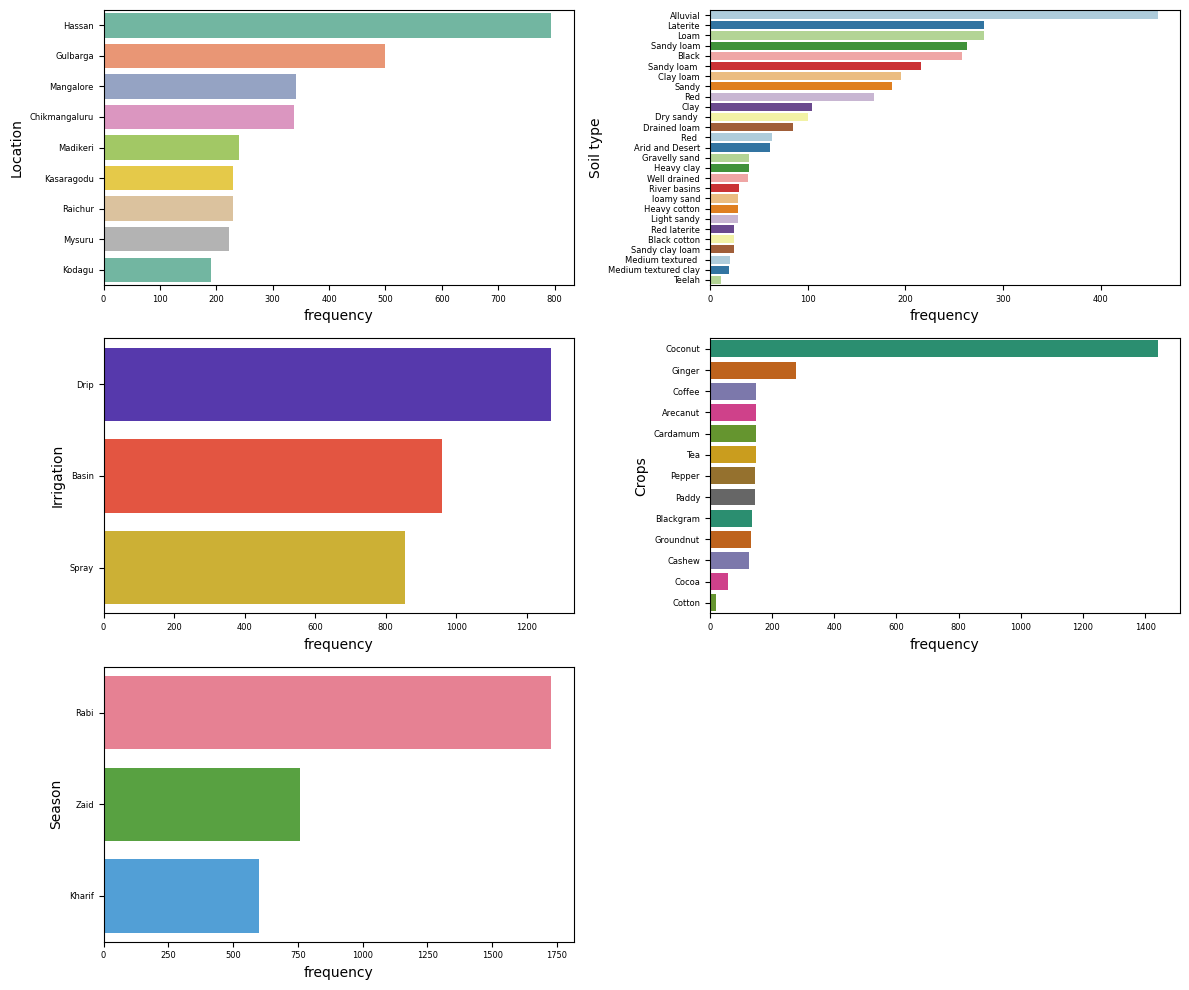

In [17]:
categorical_columns=['Location','Soil type','Irrigation','Crops','Season']
fig,axs=plt.subplots(3,2,figsize=(12,10))
axs = axs.ravel()
palette=["Set2", "Paired", "CMRmap", "Dark2", "husl"]
for ax,col,pal in zip(axs,categorical_columns,palette):
    x_par=df_new[col].value_counts().index
    y_par=df_new[col].value_counts().values
    sns.barplot(x=y_par, y=x_par,hue=x_par,palette=pal, ax=ax)
    ax.set_xlabel('frequency')
    ax.set_ylabel(col)
    ax.tick_params(labelsize=6)
axs[-1].remove()
plt.tight_layout()            
plt.show()

## Frequency of categorical columns with respect to Season:

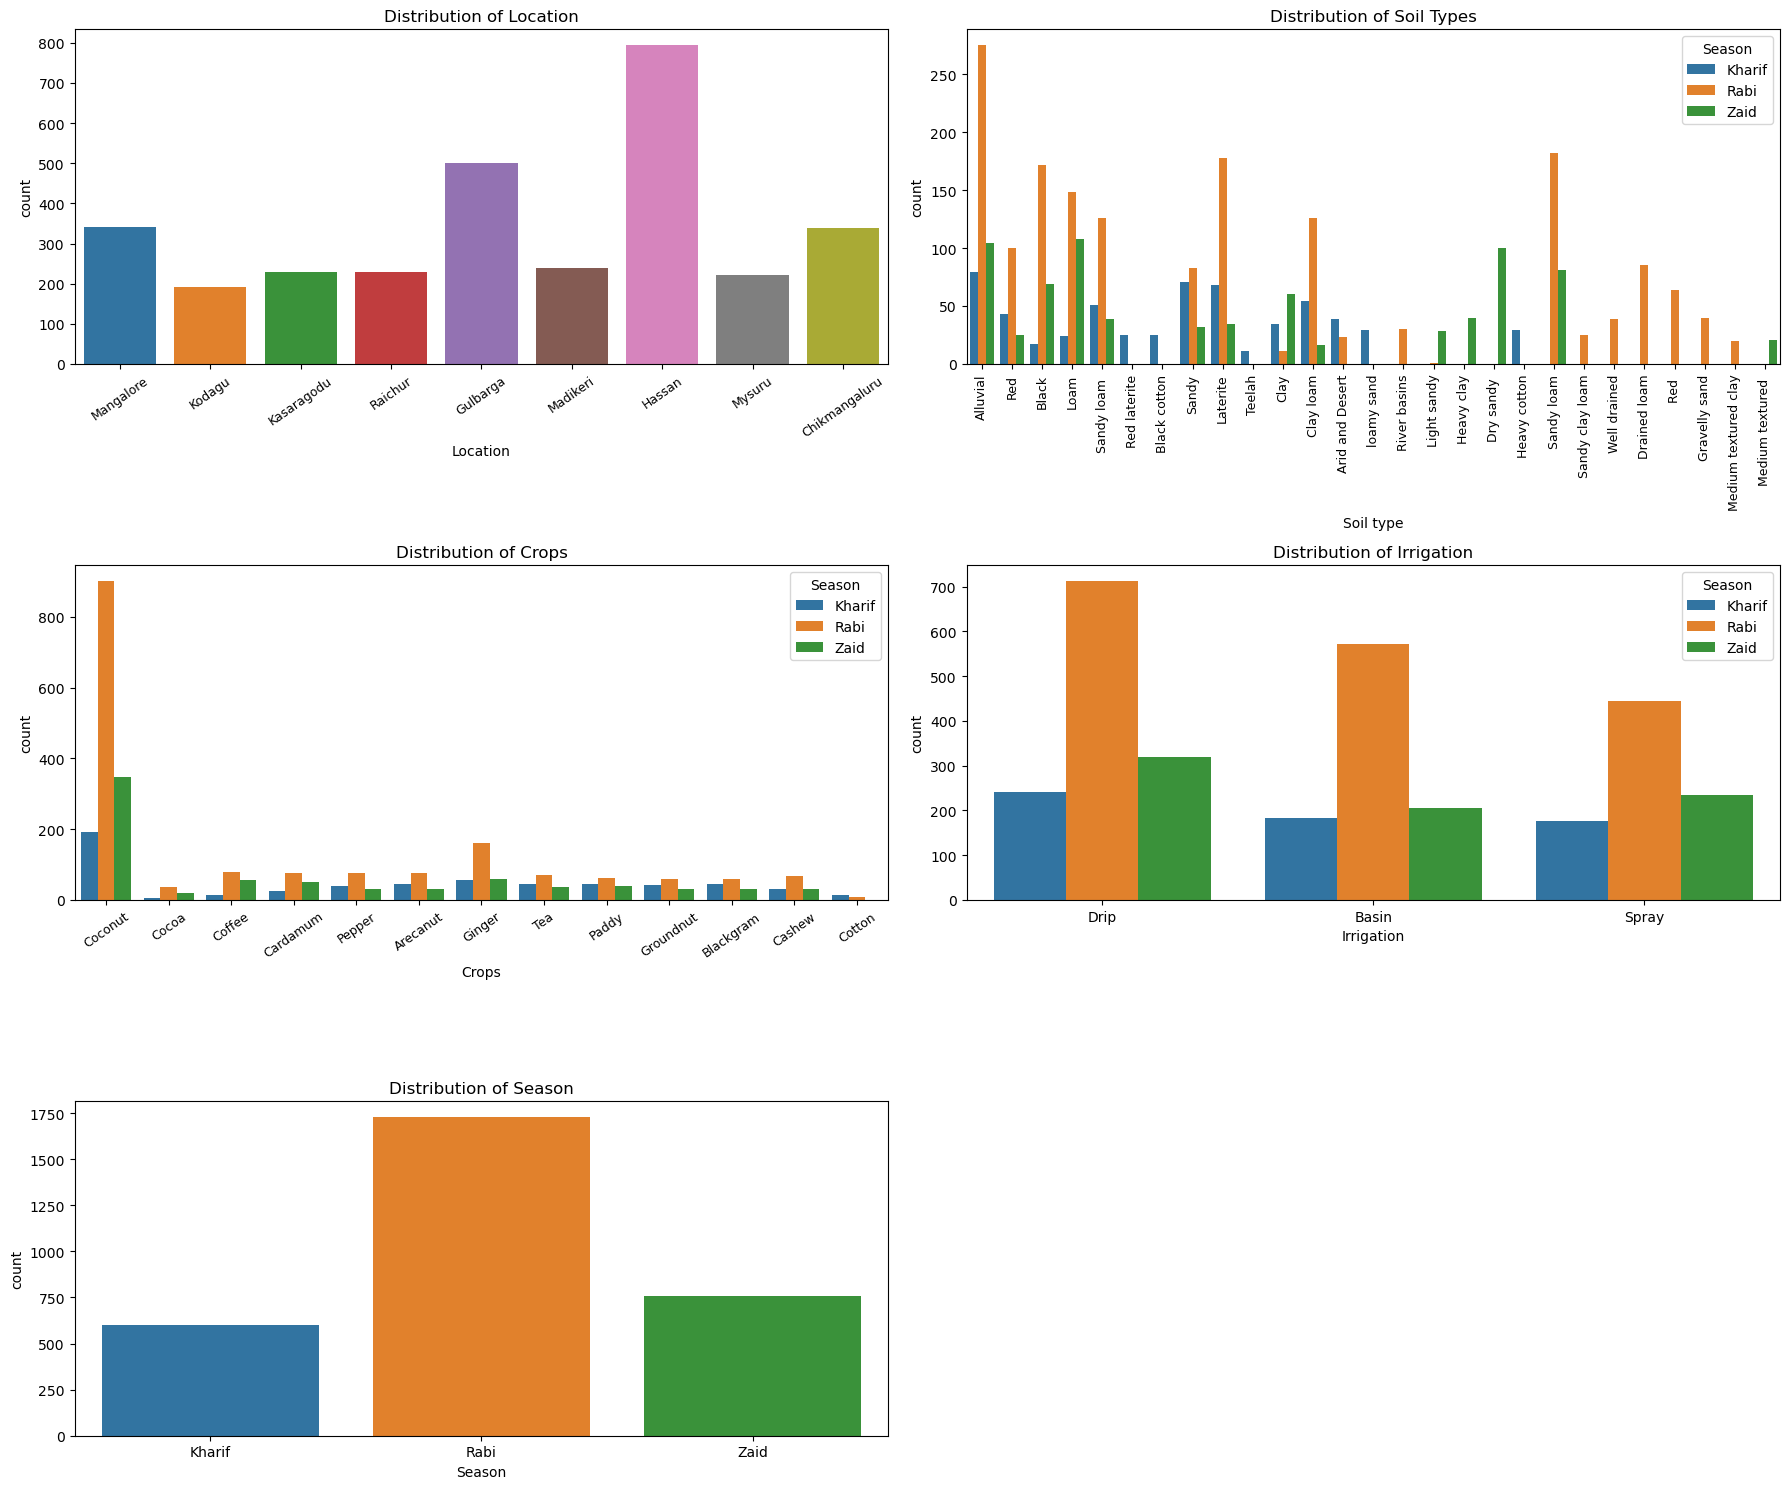

In [18]:
fig, axs = plt.subplots(3, 2, figsize=(18, 15))

sns.countplot(data=data, x=df_new['Location'],hue=df_new['Location'], ax=axs[0, 0])
axs[0, 0].set_title('Distribution of Location')
axs[0,0].tick_params(axis="x",labelsize=9,rotation=35)

sns.countplot(data=data, x=df_new['Soil type'],hue=df_new['Season'], ax=axs[0, 1])
axs[0, 1].set_title('Distribution of Soil Types')
axs[0,1].tick_params(axis="x",labelsize=9,rotation=90)

sns.countplot(data=data, x=df_new['Crops'],hue=df_new['Season'], ax=axs[1, 0])
axs[1,0].set_title('Distribution of Crops')
axs[1,0].tick_params(axis="x",labelsize=9,rotation=35)

sns.countplot(data=data, x=df_new['Irrigation'],hue=df_new['Season'], ax=axs[1, 1])
axs[1, 1].set_title('Distribution of Irrigation')

sns.countplot(data=data, x=df_new['Season'],hue=df_new['Season'], ax=axs[2, 0])
axs[2, 0].set_title('Distribution of Season')
axs[2,1].remove()

plt.tight_layout()
plt.show()

### Key Insights: 
- **Soil Types: This chart shows which soil types are suitable for different seasons.**
- **Crops: Coconut has the highest frequency, especially during the Rabi season, indicating that it is most commonly harvested in this period.**
- **Irrigation Methods: The Basin irrigation has the highest frequency, particularly during Rabi season. This suggests that the method is well-suited for winter crops.**
  <br><br>

## Distribution of numerical columns: 

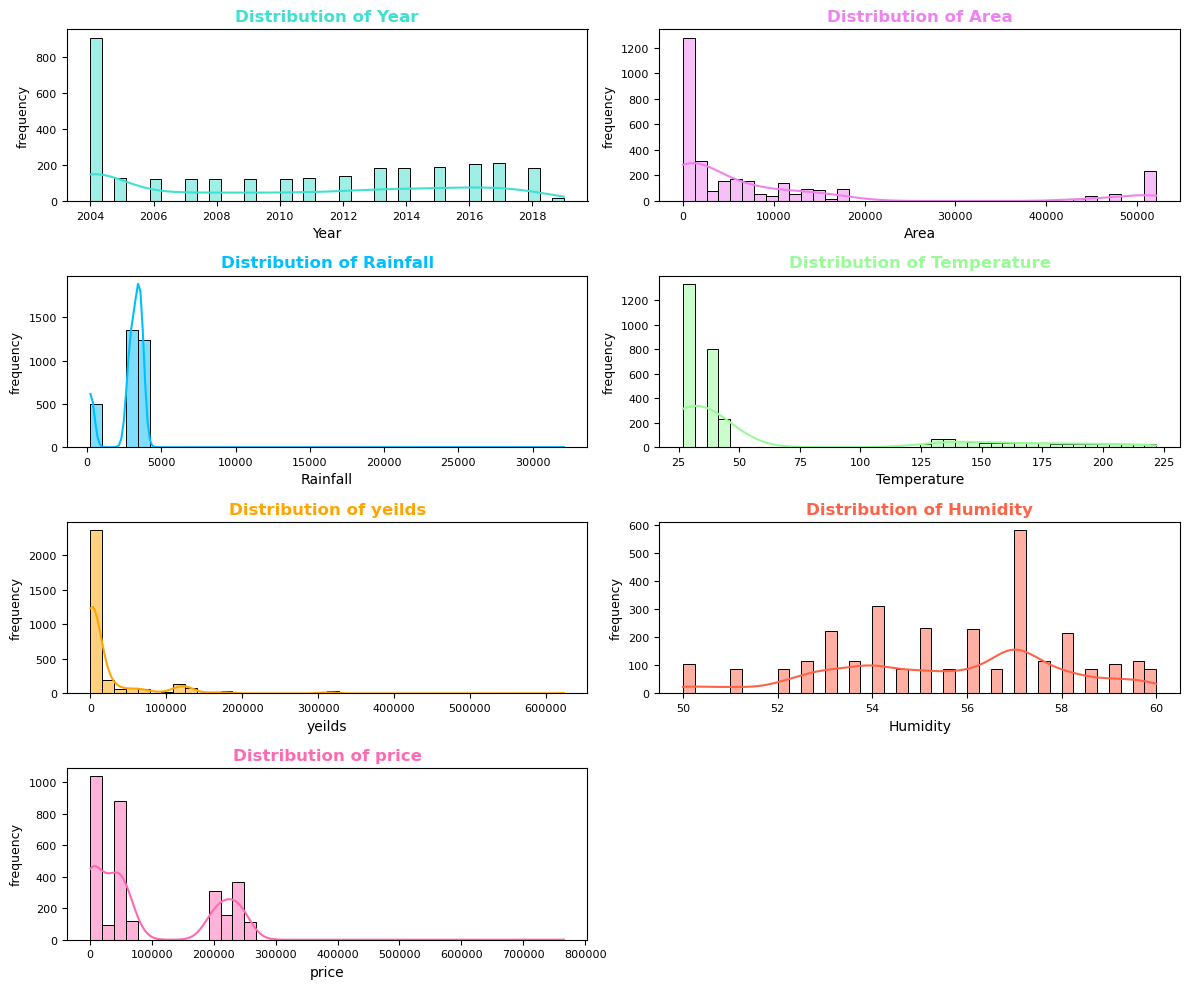

In [19]:
fig,axs=plt.subplots(4,2,figsize=(12,10))
axs = axs.ravel()
colors=['turquoise','violet','deepskyblue','palegreen','orange','tomato','hotpink']
for ax,column,col in zip(axs,numerical_columns,colors):
    sns.histplot(x=df_new[column],color=col,bins=40, kde=True,ax=ax,data=df_new)
    ax.set_title(f'Distribution of {column}',color=col, fontweight='bold')
    ax.set_ylabel('frequency',fontsize=9)
    ax.tick_params(labelsize=8)
axs[-1].remove()
plt.tight_layout()            
plt.show()

### Key Insights:
- **Year: The year 2004 shows an unusually high frequency of data entries. From 2006 to 2018, the data is more evenly distributed.**
- **Area: Most of the lands have small areas, It's values concentrated near zero. The distribution is right-skewed, showing that small plots dominate but large ones stretch the range.**
- **Temperature: The histogram shows that most temperature values are concentrated around 27°C, indicating a warm and moderate climate in the these regions. The distribution is right-skewed, meaning that while most observations fall within the lower temperature range, a few extend toward higher values, although temperatures above 50°C are likely unrealistic or rare.**
- **Humidity: The distribution is fairly symmetrical, with a slight skew to the left, indicating that most observations fall within a narrow and stable range between 50% and 60%. This suggests a consistently humid climate**

<br><br>

In [20]:
df_new[df_new['price']>400000]


,Year,Location,Area,Rainfall,Temperature,Soil type,Irrigation,yeilds,Humidity,Crops,price,Season
2510,2014,Mangalore,7028,3522.8,38.0,Laterite,Drip,3472.0,59.0,Cashew,765551.0,Rabi


In [21]:
df_new[df_new['Rainfall']>5000]

,Year,Location,Area,Rainfall,Temperature,Soil type,Irrigation,yeilds,Humidity,Crops,price,Season
165,2017,Gulbarga,66,32096.0,162.0,Black,Drip,5518.0,57.0,Cardamum,24848.0,Kharif


In [22]:
df_new.drop(df_new[df_new['price']>400000].index,inplace=True) #remove the row where price>40000
df_new.drop(df_new[df_new['Rainfall']>5000].index,inplace=True) #remove the row where Rainfall > 30000

## Distribution Crops with numerical columns:

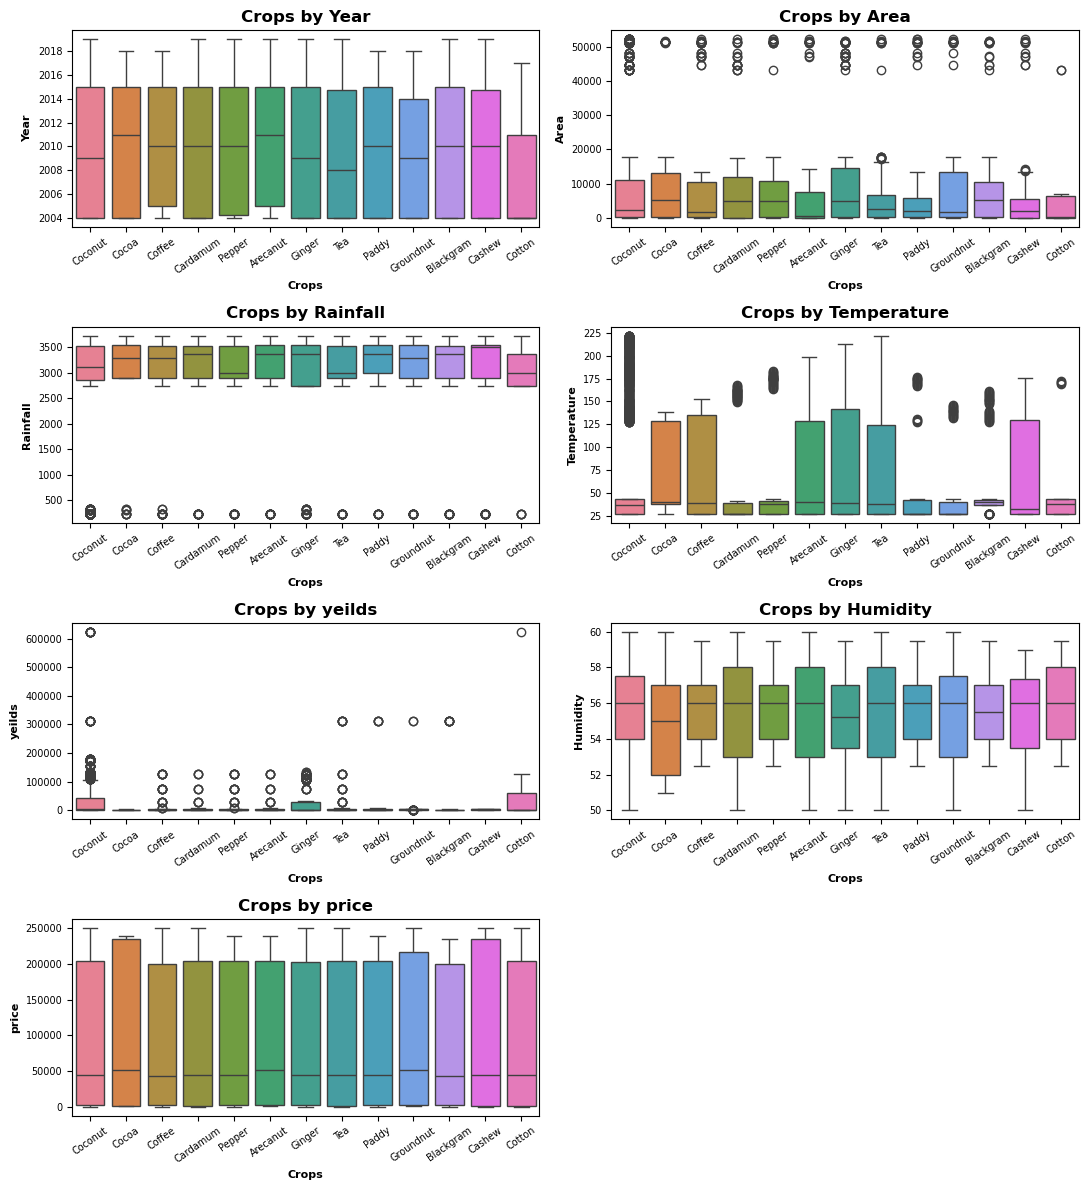

In [23]:
fig,axs=plt.subplots(4,2,figsize=(11,12))
axs = axs.ravel()
for col,ax in zip(numerical_columns,axs):
    sns.boxplot(x='Crops',y=col,hue='Crops',ax=ax,data=df_new)
    ax.set_title(f"Crops by {col}",fontweight='bold')
    ax.set_xlabel('Crops',fontsize=8,fontweight='bold')
    ax.set_ylabel(col,fontsize=8,fontweight='bold')
    ax.tick_params(axis='x',labelsize=7,rotation=35)
    ax.tick_params(axis='y',labelsize=7)
    
axs[-1].remove()
plt.tight_layout()
plt.show()


### Key Insights
- **The distribution of Year, Humidity and price across crops appears to be relatively stable.** 
 **Their medians remain consistent, showing that these variables don't vary much between different crops.**
- **There are a large number of outliers in Area, Temperature and Rainfall.**
- **The outliers of Area are mostly above 40000.**
- **Rainfall shows outliers mostly below 500mm, indicating that some crops are cultivated even in very low rainfall conditions.**
- **The distribution of temperture across crops shows a relatively stable median.**
<br><br>

## Location with Temperature

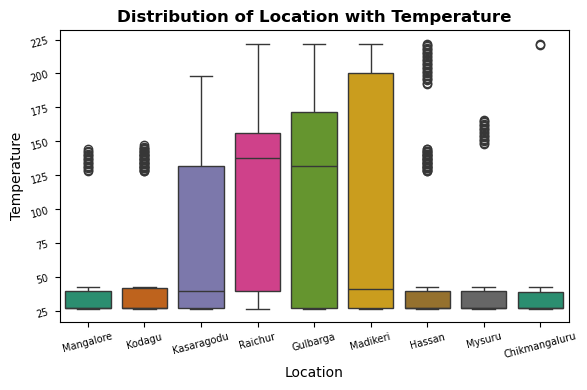

In [24]:
plt.subplots(figsize=(6,4))
sns.boxplot(x='Location',y='Temperature',hue='Location',palette='Dark2' ,data=df_new)
plt.tick_params(labelsize=7,rotation=15)
plt.title('Distribution of Location with Temperature',fontweight='bold')

plt.tight_layout()
plt.show()

### Key Insights:  
- **Regions such as Mangalore, Kodagu, Hassan, Mysuru, and Chikmagalur exhibit relatively low medians and narrow spreads,  
yet display the presence of extreme outliers.**  
- **Regions such as Kasaragodu, Raichur and Gulbarga reveal wider spreads and higher medians. It seems that these regions  
have many outliers, indicative of unusual or rare climate conditions beyond the normal range.**
- **mountain/coastal areas such as kodagu,Mangalore and Chikmagaluru are more stable climate,inland areas such as Raichur and Gulbarga fluctuate greatly.**
  <br><br>


### Adjustment of Unrealistic Temperature Outliers:

In [25]:
def corrected_temperature(temp):
    if 100<temp<=150:
        return temp%100
    elif temp>150:
        return temp//10+10
    else:
        return temp
df_new['Temperature']=df_new['Temperature'].apply(corrected_temperature)

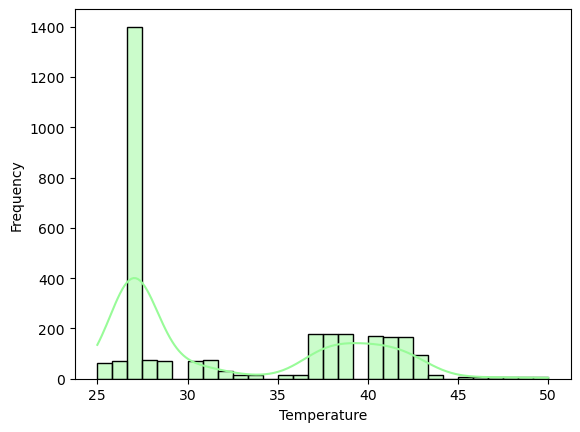

In [26]:
sns.histplot(x='Temperature',data=df_new,bins=30,kde=True,color='palegreen')
plt.ylabel('Frequency')
plt.show()

## Boxplot of categorical columns with yeilds:

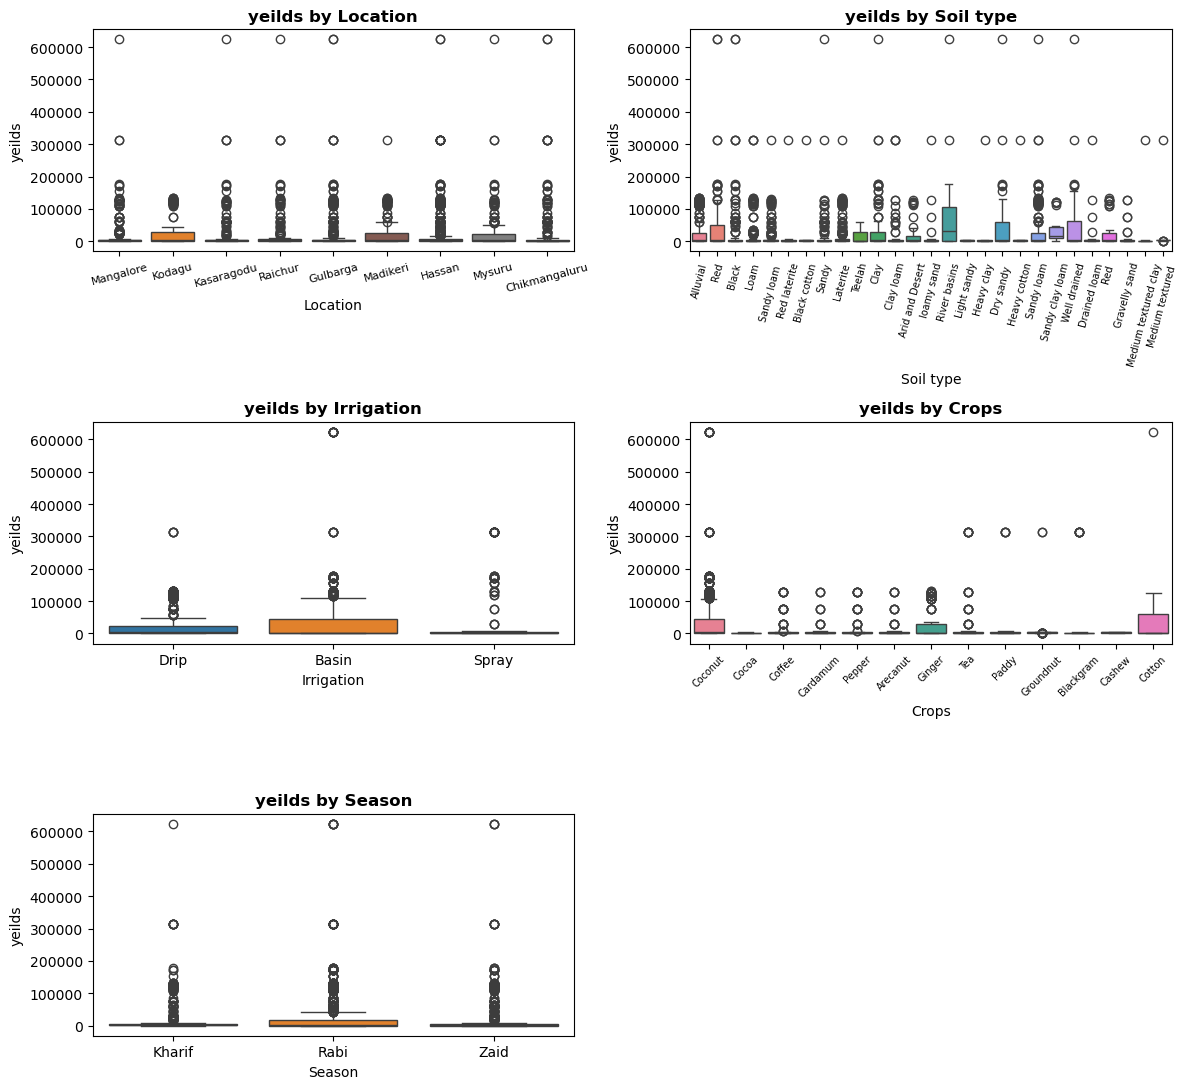

In [27]:
fig,axs=plt.subplots(3,2,figsize=(12,11))
axs = axs.ravel()
categorical_columns=['Location','Soil type','Irrigation','Crops','Season']

for ax,col in zip(axs,categorical_columns):
    sns.boxplot(x=col,y='yeilds',hue=col,ax=ax,data=df_new)
    ax.set_title(f'yeilds by {col}',fontweight='bold')
axs[0].tick_params(axis='x',rotation=15,labelsize=8)
axs[1].tick_params(axis='x',rotation=75,labelsize=7)
axs[3].tick_params(axis='x',rotation=45,labelsize=7)
axs[-1].remove()
plt.tight_layout()
plt.show()

In [28]:
len(df_new[df_new['yeilds']>200000])

39

## Rainfalland and Temperature versus yeilds:

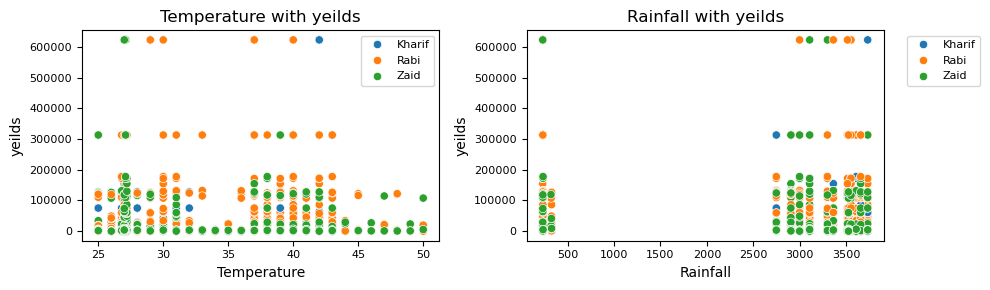

In [29]:
fig,axs=plt.subplots(1,2,figsize=(10,3))
sns.scatterplot(x='Temperature',y='yeilds',hue='Season',data=df_new,ax=axs[0])
axs[0].legend(loc='best',fontsize=8)
axs[0].tick_params(labelsize=8)
axs[0].set_title('Temperature with yeilds')

sns.scatterplot(x='Rainfall',y='yeilds',hue='Season',data=df_new,ax=axs[1])
axs[1].legend(bbox_to_anchor=(1.05,1),loc='best',fontsize=8)
axs[1].tick_params(labelsize=8)
axs[1].set_title('Rainfall with yeilds')

plt.tight_layout()
plt.show()


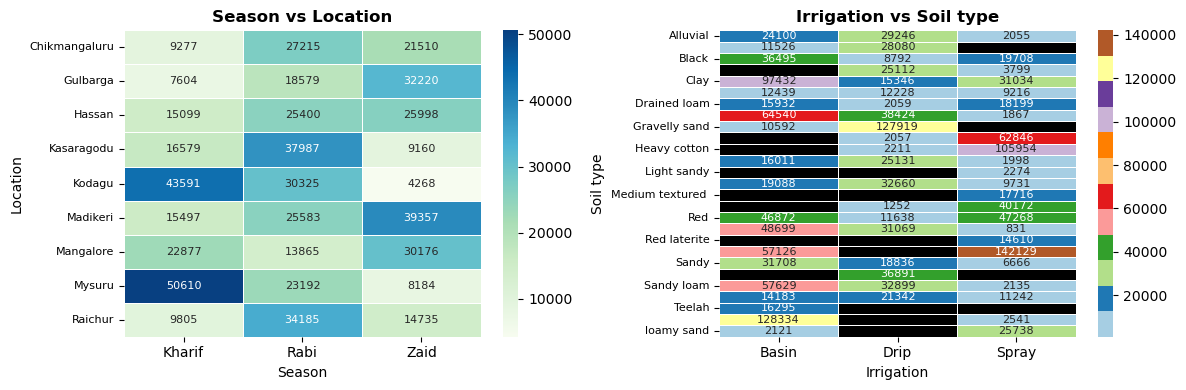

In [30]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
glue = df_new.pivot_table(index="Location", columns="Season", values="yeilds",aggfunc='mean')
sns.heatmap(glue,annot=True,fmt='.0f',cmap='GnBu',annot_kws={"size": 8},linewidth=.5,ax=axs[0])
axs[0].set_title("Season vs Location",fontweight='bold')
axs[0].tick_params(axis='y',labelsize=8)

glue1 = df_new.pivot_table(index="Soil type", columns="Irrigation", values="yeilds",aggfunc='mean')
cmap = sns.color_palette('Paired', as_cmap=True)
cmap.set_bad(color='black')
sns.heatmap(glue1,annot=True,fmt='.0f',cmap=cmap,annot_kws={"size": 8},linewidth=.5,ax=axs[1])
axs[1].set_title("Irrigation vs Soil type",fontweight='bold')
axs[1].tick_params(axis='y',labelsize=8)
plt.tight_layout()
plt.show()

### Key Insights:
- **Kharif season is dominant in specific regions such as Mysuru and Kodagu, showing the highest agricultural activity during this period.**  
- **Zaid season generally gives lower yields across most locations.**  
- **Basin irrigation is highly effective on certain soil types, while Spray irrigation almost always results in lower yields.**  
- **Spray irrigation consistently results in lower yields compared to Basin and Drip.**
  <br><br><br>

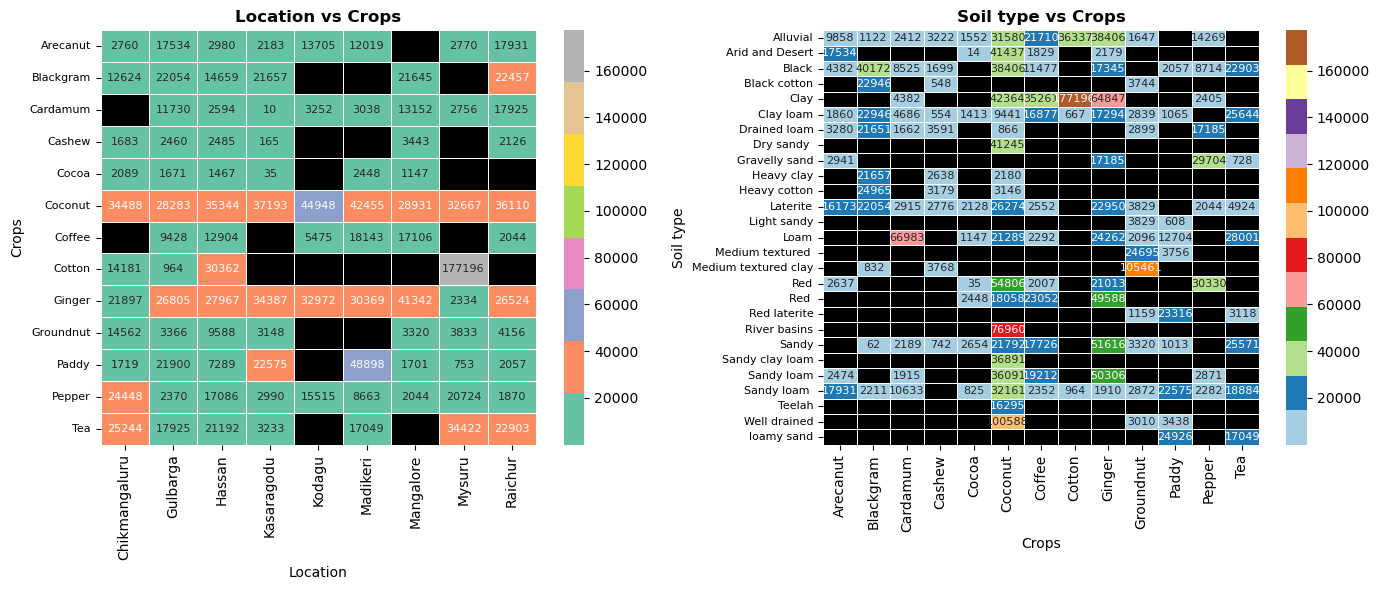

In [31]:
fig,axs=plt.subplots(1,2,figsize=(14,6))
glue = df_new.pivot_table(index="Crops", columns="Location", values="yeilds",aggfunc='mean')
cmap = sns.color_palette('Set2', as_cmap=True)
cmap.set_bad(color='black')
sns.heatmap(glue,annot=True,fmt='.0f',cmap=cmap,annot_kws={"size": 8},linewidth=.5,ax=axs[0])
axs[0].set_title("Location vs Crops",fontweight='bold')
axs[0].tick_params(axis='y',labelsize=8)

glue1 = df_new.pivot_table(index="Soil type", columns="Crops", values="yeilds",aggfunc='mean')
cmap = sns.color_palette('Paired', as_cmap=True)
cmap.set_bad(color='black')
sns.heatmap(glue1,annot=True,fmt='.0f',cmap=cmap,annot_kws={"size": 8},linewidth=.5,ax=axs[1])
axs[1].set_title("Soil type vs Crops",fontweight='bold')
axs[1].tick_params(axis='y',labelsize=8)

plt.tight_layout()
plt.show()

### Key Insights:
- **Coconut shows consistently high yields across multiple locations and soil type.**
- **Cotton yield is extremely high in Mysuru.**
- **Some crops such as Cashew and Cocoa have low yields, regardless of environmental conditions.**
  <br><br>

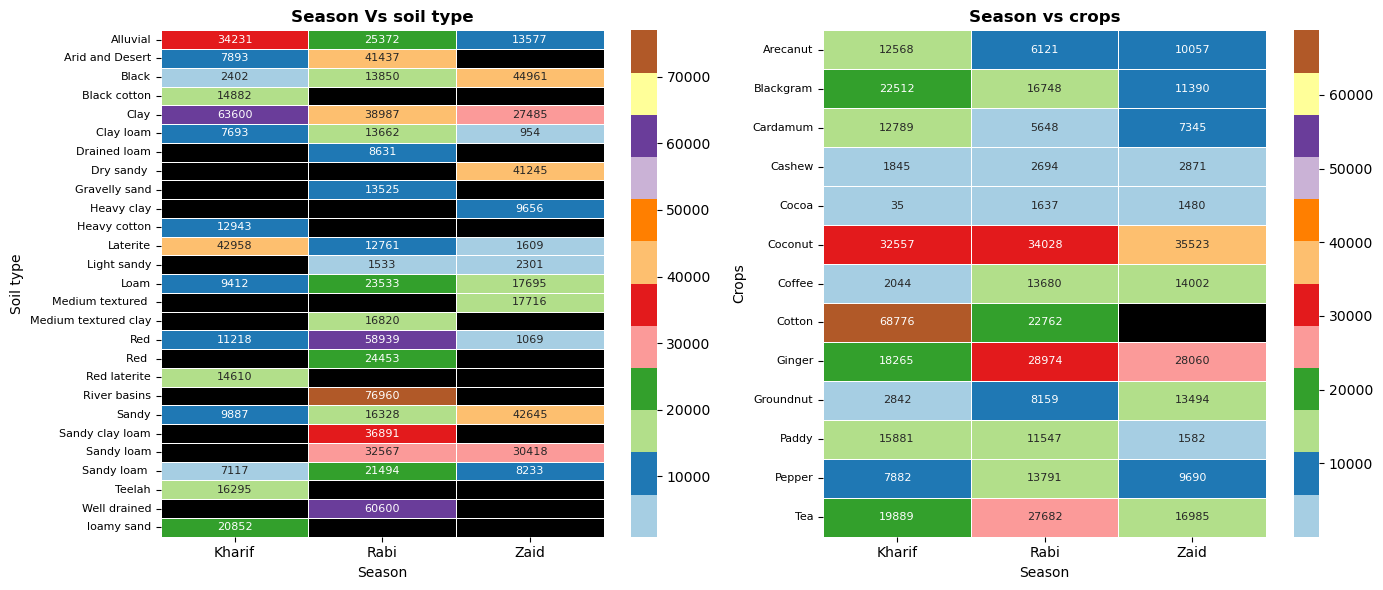

In [32]:
fig,axs=plt.subplots(1,2,figsize=(14,6))
glue = df_new.pivot_table(index="Soil type", columns="Season", values="yeilds",aggfunc='mean')
cmap = sns.color_palette('Paired', as_cmap=True)
cmap.set_bad(color='black')
sns.heatmap(glue,annot=True,fmt='.0f',cmap=cmap,annot_kws={"size": 8},linewidth=.5,ax=axs[0])
axs[0].set_title("Season Vs soil type",fontweight='bold')
axs[0].tick_params(axis='y',labelsize=8)

glue1 = df_new.pivot_table(index="Crops", columns="Season", values="yeilds",aggfunc='mean')
cmap = sns.color_palette('Paired', as_cmap=True)
cmap.set_bad(color='black')
sns.heatmap(glue1,annot=True,fmt='.0f',cmap=cmap,annot_kws={"size": 8},linewidth=.5,ax=axs[1])
axs[1].set_title("Season vs crops",fontweight='bold')
plt.tick_params(axis='y',labelsize=8)
plt.tight_layout()
plt.show()

### Key Insights:
- **Some soil types show very limited productivity in Zaid season.**
- **Clay soil shows very high yields.**
- **Coconut maintains high yields across all three seasons.**
- **Cotton peaks in Kharif, drops in Rabi, and is almost absent in Zaid.**
- **Seasonality affects crops differently: some (Coconut) are stable, while others (Cotton, Tea) are season-sensitive.**
  <br><br>

## Price distribution with numerical variables: 

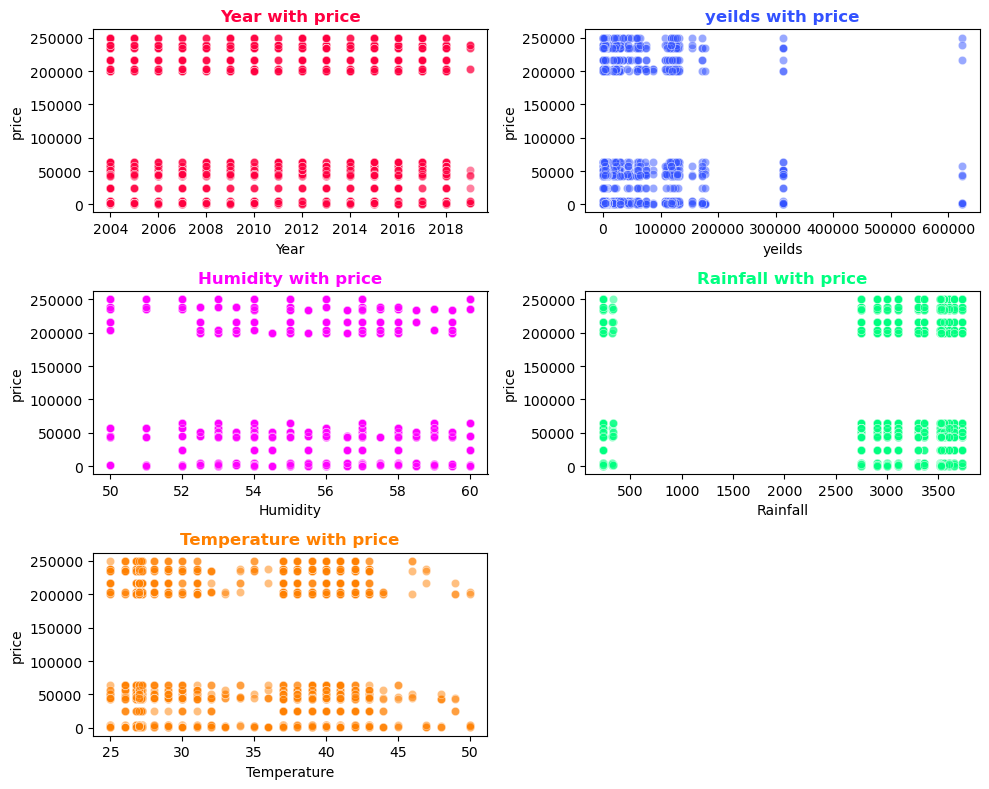

In [33]:
plots=[('Year','price','#ff0040'),
      ('yeilds','price','#3352ff'),
      ('Humidity','price','#ff00ff'),
      ('Rainfall','price','#00ff80'),
       ('Temperature','price','#ff8000')]
fig,axs=plt.subplots(3,2,figsize=(10,8))
axs=axs.ravel()
for i,(x,y,color) in enumerate(plots):
    sns.scatterplot(x=x,y=y,data=df_new,ax=axs[i],marker='o',alpha=0.5,color=color)
    axs[i].set_title(f"{x} with price",color=color,fontweight='bold')

axs[-1].remove()
plt.tight_layout()
plt.show()

## Price distribution based on categorical variables:

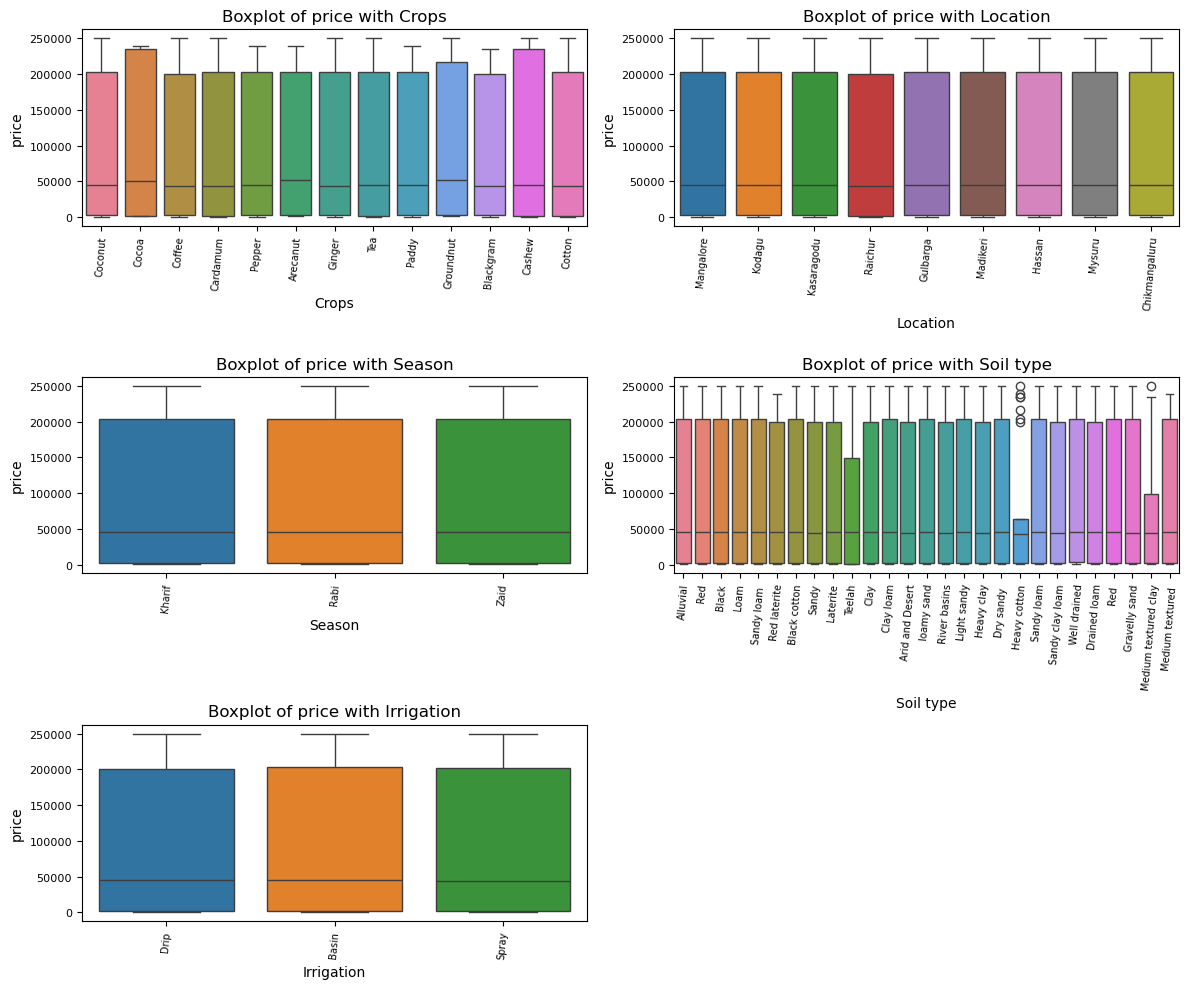

In [34]:
fig,axs=plt.subplots(3,2,figsize=(12,10))
axs = axs.ravel()
columns=['Crops','Location','Season','Soil type','Irrigation']
for ax,col in zip(axs,columns):
    sns.boxplot(x=col,y='price' ,hue=col ,ax=ax,data=df_new)
    ax.set_title(f"Boxplot of price with {col}")
    ax.tick_params(axis='x',labelsize=7,rotation=85)
    ax.tick_params(axis='y',labelsize=8)
axs[-1].remove()
plt.tight_layout()
plt.show()

### Key insights:  
- **The analysis exhibit that price is not strongly determind by the features included in the dataset.**
- **The median price remains almost the same across these factors.**
- **Crops prices fall into two distinct range:low and high prices.**    
- **The most likely explanation is that prices are recorded in different units or market contexts such as retail or wholesale.**  
<br><br>

## Distribution of Year with hue=crops:

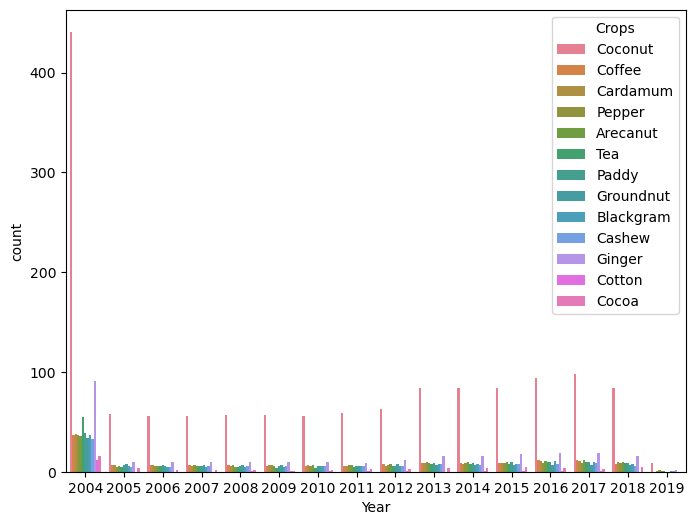

In [35]:
plt.subplots(figsize=(8,6))
sns.countplot(x='Year',hue='Crops',data=df_new)
plt.show()

### Lineplot of Year vs yeilds:

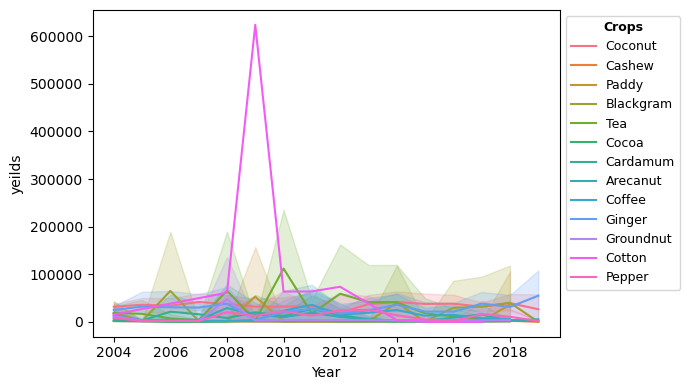

In [36]:
plt.figure(figsize=(7,4))
df_sorted=df_new.sort_values(by=['Year','yeilds'])
sns.lineplot(x='Year',y='yeilds',hue='Crops',data=df_sorted)
plt.legend(title='Crops',title_fontproperties={'weight':'bold','size':9},bbox_to_anchor=(1,1),loc='upper left',fontsize=9)
plt.tight_layout()
plt.show()

### Key insights:
- **This lineplot shows that the yeilds of Cotton sharply increase around the year 2009. This appears to be a significant outlier compared to all  
other data points.**
- **The Cotton yeilds are much lower in other years.**   
- **Other crops show slightly fluctuating yeilds over the years.**
<br><br>

### Year and Crops fluctuations on yeilds:

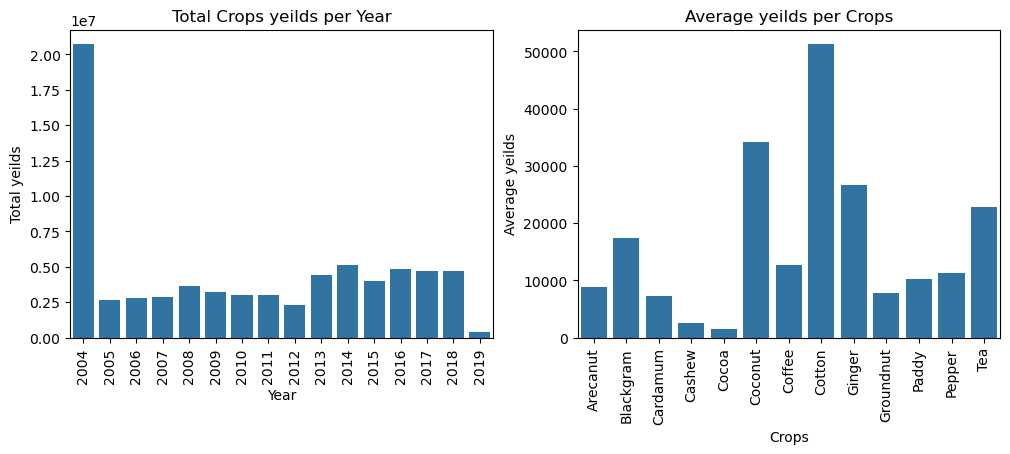

In [37]:
df_grouped=df_new.groupby('Year').sum().reset_index()
fig,axs=plt.subplots(1,2,figsize=(12,4))
sns.barplot(x='Year',y='yeilds',data=df_grouped,ax=axs[0])
axs[0].set_title('Total Crops yeilds per Year')
axs[0].set_xlabel('Year')
axs[0].set_ylabel('Total yeilds')
axs[0].tick_params(axis='x',rotation=90)

average_yeilds_per_crop=df_new.groupby('Crops')['yeilds'].mean().reset_index()
sns.barplot(x='Crops',y='yeilds',data=average_yeilds_per_crop,ax=axs[1])
axs[1].set_title('Average yeilds per Crops')
axs[1].set_xlabel('Crops')
axs[1].set_ylabel('Average yeilds')
axs[1].tick_params(axis='x',rotation=90)
plt.tight_layout
plt.show()

### Key Insights:
- **Total Crops yeilds per Year chart reveal massive spike in total yeilds in 2004. This caused by a different crop, or a combination of crops, and was a much larger even than the Cotton spike in 2009. This shows that the largest production occurred in 2004, not in 2009**   
- **Total yeilds ramain fairly consistent from 2005 to 2018.**
- **Total yeilds have declined sharply in 2019.** 
- **Coconut and cotton have higher average yeilds than other crops.**
- **The line chart highlights that large, single-year spikes in specific crops (like Cotton in 2009) can skew the "average" and "total" yield graphs.** 
<br><br>

### Average yeilds per crops in 2004:

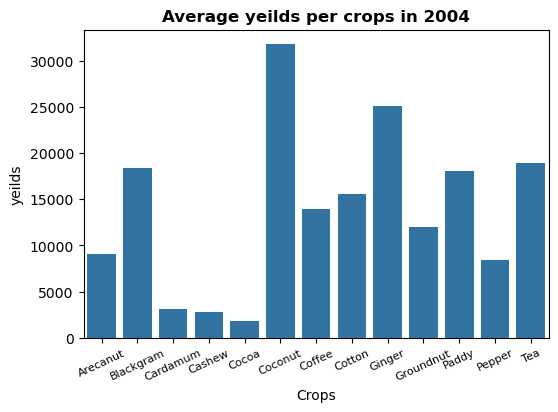

In [38]:
plt.figure(figsize=(6,4))
year_filttered=df_new[df_new['Year']==2004]
average_yeilds=year_filttered.groupby('Crops')['yeilds'].mean().reset_index()
sns.barplot(x='Crops',y='yeilds',data=average_yeilds)
plt.xticks(rotation=25,fontsize=8)
plt.title('Average yeilds per crops in 2004',fontweight='bold')
plt.show()

### Average price over Crops:

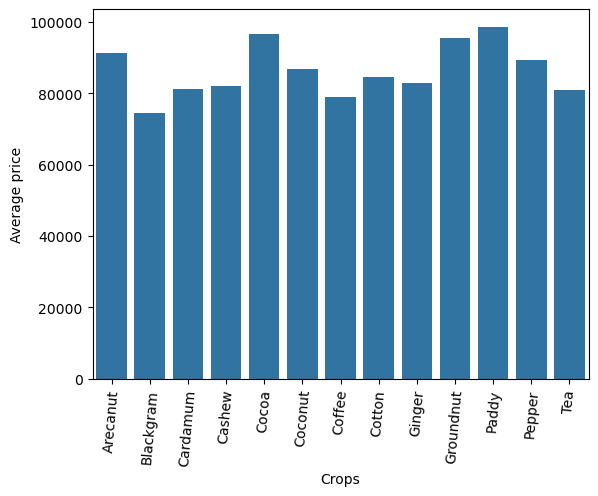

In [39]:
average_price_per_crop=df_new.groupby('Crops')['price'].mean().reset_index()
sns.barplot(x='Crops',y='price',data=average_price_per_crop)
plt.ylabel('Average price')
plt.xlabel('Crops')
plt.xticks(rotation=85)
plt.show()

### Year vs yeilds:

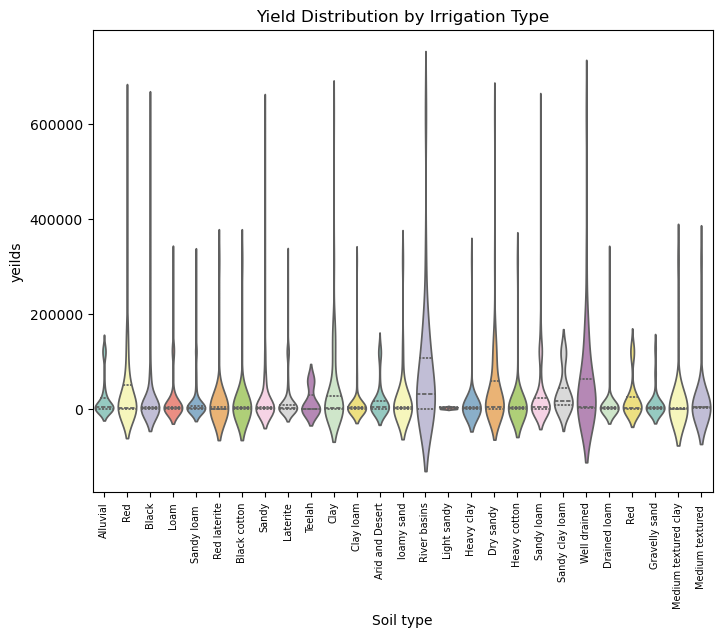

In [40]:
plt.figure(figsize=(8,6))
sns.violinplot(x='Soil type',y='yeilds',hue='Soil type',inner='quartile',palette='Set3',data=df_new)
plt.title('Yield Distribution by Irrigation Type')
plt.xticks(rotation=90,fontsize=7)
plt.show()

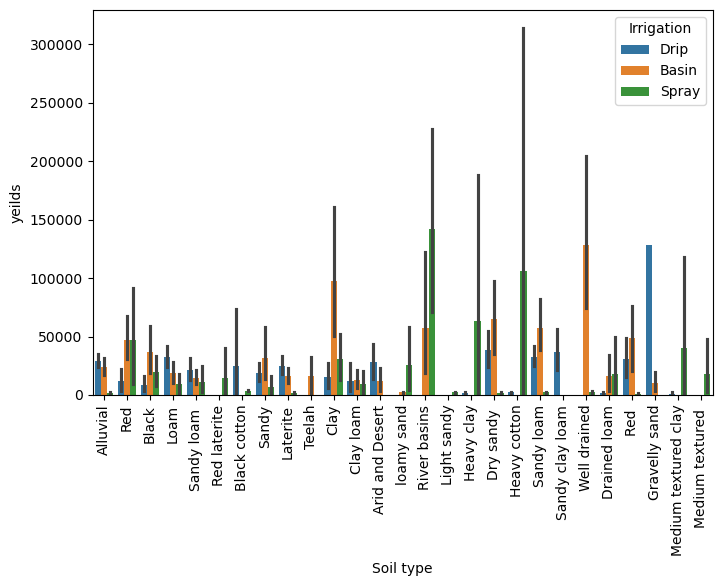

In [41]:
plt.figure(figsize=(8,5))
sns.barplot(x='Soil type',y='yeilds',hue='Irrigation',data=df_new)
plt.xticks(rotation=90)
plt.show()

### Price & yeilds and Rainfall fluctuations on Year:

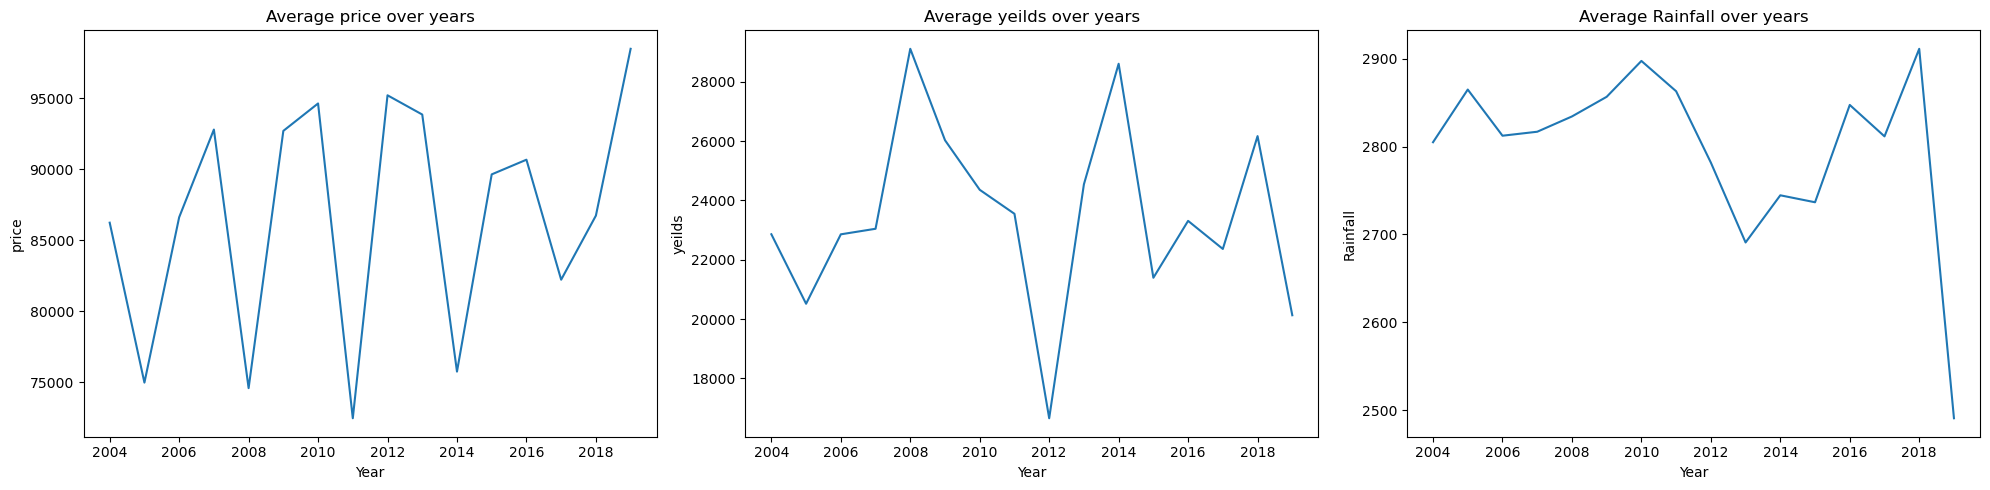

In [42]:
columns=['price','yeilds','Rainfall']
fig,axs=plt.subplots(1,3,figsize=(20,5))
axs=axs.ravel()
for i,col in enumerate(columns):
    Average_columns_over_year=df_new.groupby('Year')[col].mean().reset_index()
    sns.lineplot(x='Year',y=col,data=Average_columns_over_year,ax=axs[i])
    axs[i].set_title(f'Average {col} over years')
plt.tight_layout()
plt.show()

In [43]:
df_new.groupby('Year')[['price','yeilds','Rainfall']].mean().pct_change().reset_index()

,Year,price,yeilds,Rainfall
0,2004,NaN,NaN,NaN
1,2005,-0.130591,-0.102519,0.021376
2,2006,0.155272,0.114122,-0.018339
3,2007,0.071321,0.008194,0.001609
4,2008,-0.196212,0.263331,0.006176
5,2009,0.242860,-0.105884,0.007893
6,2010,0.020833,-0.064220,0.014296
7,2011,-0.234240,-0.033230,-0.011907
8,2012,0.313822,-0.292738,-0.028375
9,2013,-0.014231,0.473697,-0.032687


### Key Insights:
- **Rainfall is closely link to yeild. Years with lower rainfall, such as 2012 and 2019, are associated with significant declines in yield,  
whereas higher rainfall is generally accompanied by increased production.**
- **The price exhibits significant volatility, and variation in rainfall and yeilds appear to have no impact on its behavior.**
  <br><br>

In [44]:
df_new.groupby('Year')[['price','Rainfall','yeilds']].agg(['mean','sum']).reset_index()

Year         price                 Rainfall                   yeilds  \
                  mean         sum         mean        sum          mean   
0   2004  86248.674393  78141299.0  2805.024503  2541352.2  22858.727252   
1   2005  74985.375000   9598128.0  2864.985938   366718.2  20515.281250   
2   2006  86628.504065  10655306.0  2812.445528   345930.8  22856.528455   
3   2007  92806.975806  11508065.0  2816.970161   349304.3  23043.814516   
4   2008  74597.169355   9250049.0  2834.368548   351461.7  29111.959677   
5   2009  92713.869919  11403806.0  2856.739837   351379.0  26029.462114   
6   2010  94645.422764  11641387.0  2897.579675   356402.3  24357.861789   
7   2011  72475.637795   9204406.0  2863.077953   363610.9  23548.462047   
8   2012  95220.121429  13330817.0  2781.837143   389457.2  16654.936214   
9   2013  93865.077348  16989579.0  2690.906077   487054.0  24544.329724   
10  2014  75761.422222  13637056.0  2744.608889   494029.6  28607.994333   
11  2015  89650.919355  16675071.0  2736.675269   509021.6  21392.224946   
12  2016  90684.526570  18771697.0  2847.482126   589428.8  23310.077198   
13  2017  82233.985782  17351371.0  2811.701422   593269.0  22363.355782   
14  2018  86745.618785  15700957.0  2911.388398   526961.3  26167.762818   
15  2019  98494.500000   1772901.0  2490.777778    44834.0  20127.944444   

                 
            sum  
0   20710006.89  
1    2625956.00  
2    2811353.00  
3    2857433.00  
4    3609883.00  
5    3201623.84  
6    2996017.00  
7    2990654.68  
8    2331691.07  
9    4442523.68  
10   5149438.98  
11   3978953.84  
12   4825185.98  
13   4718668.07  
14   4736365.07  
15    362303.00

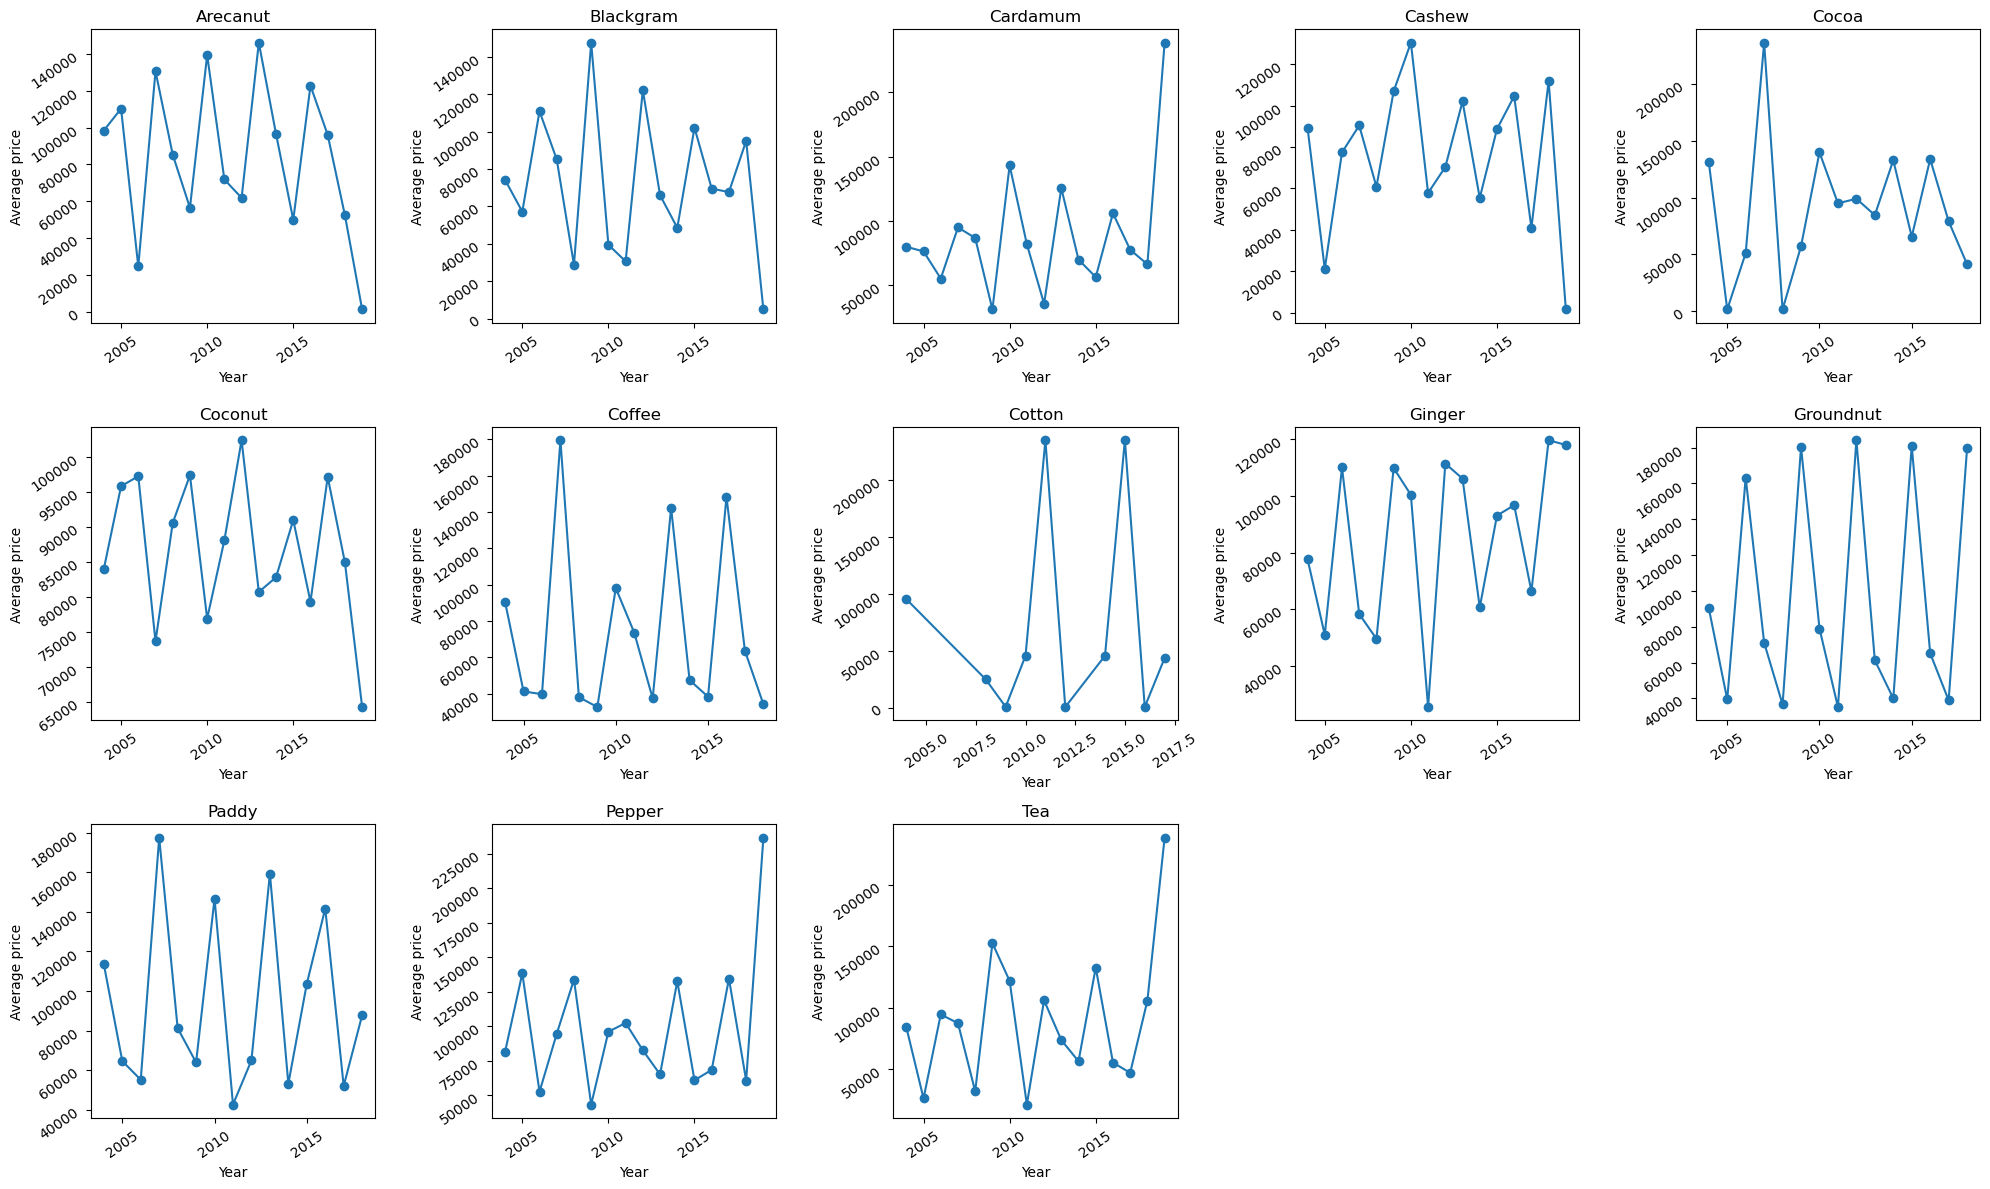

In [45]:
df_sorted=df_new.sort_values(by=['Year','Crops'])
crops=df_sorted['Crops'].unique()
fig,axs=plt.subplots(3,5,figsize=(20,12))
axs=axs.ravel()
for i,crop in enumerate(crops):
    data_crop=df_sorted[df_sorted['Crops']==crop]
    average_price=data_crop.groupby('Year')['price'].mean().reset_index()
    axs[i].plot('Year','price',data=average_price,marker='o',label=crop)
    axs[i].set_title(crop)
    axs[i].set_xlabel('Year')
    axs[i].set_ylabel('Average price')
    axs[i].tick_params(rotation=35)
for j in range(len(crops),len(axs)):
    fig.delaxes(axs[j])
plt.tight_layout()
plt.show()

### Average of price and yeilds on irrigation:

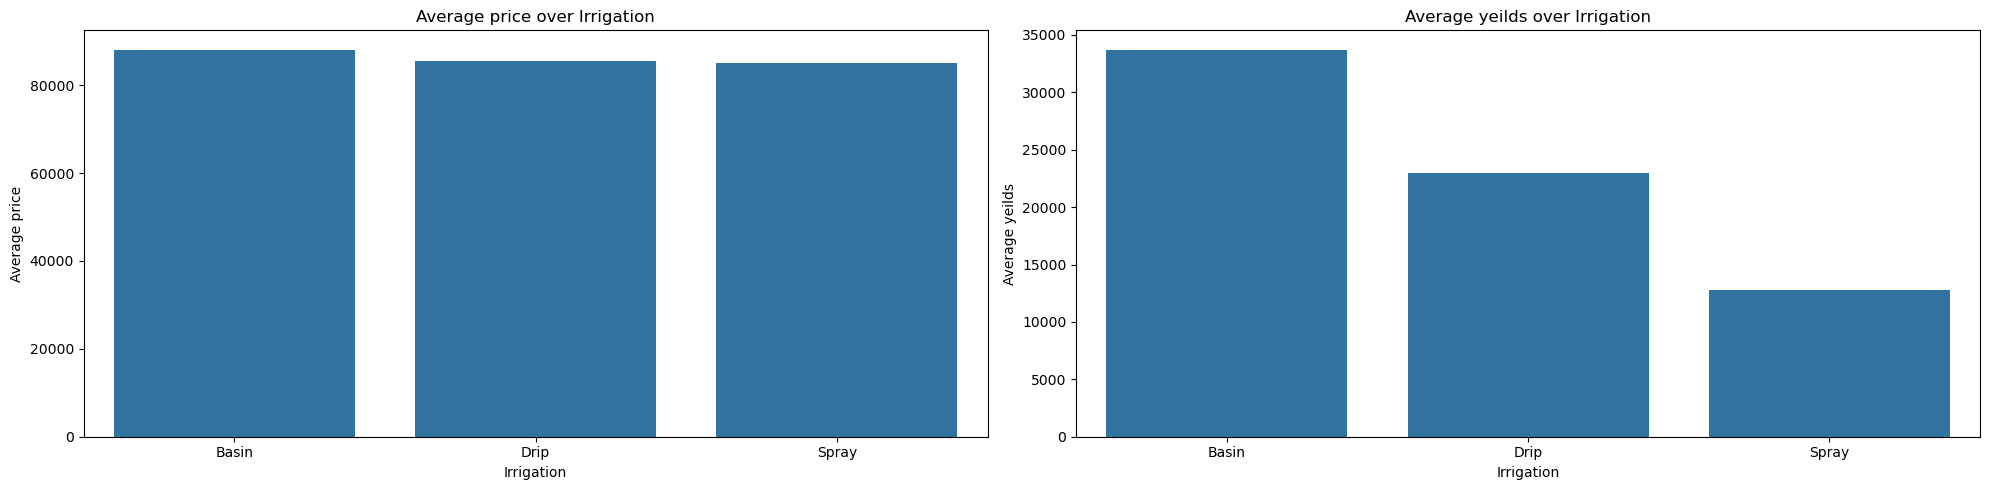

In [46]:
columns=['price','yeilds']
fig,axs=plt.subplots(1,2,figsize=(20,5))
axs=axs.ravel()
for i,col in enumerate(columns):
    Average_columns_over_Irrigation=df_new.groupby('Irrigation')[col].mean().reset_index()
    sns.barplot(x='Irrigation',y=col,data=Average_columns_over_Irrigation,ax=axs[i])
    axs[i].set_ylabel(f'Average {col}')
    axs[i].set_title(f'Average {col} over Irrigation')
plt.tight_layout()
plt.show()

### Key Insights:
- **Irrigation type strongly influences yeilds, but has little effect on average price**   
- **The Basin irrigation have the highest yeilds.**
<br><br>

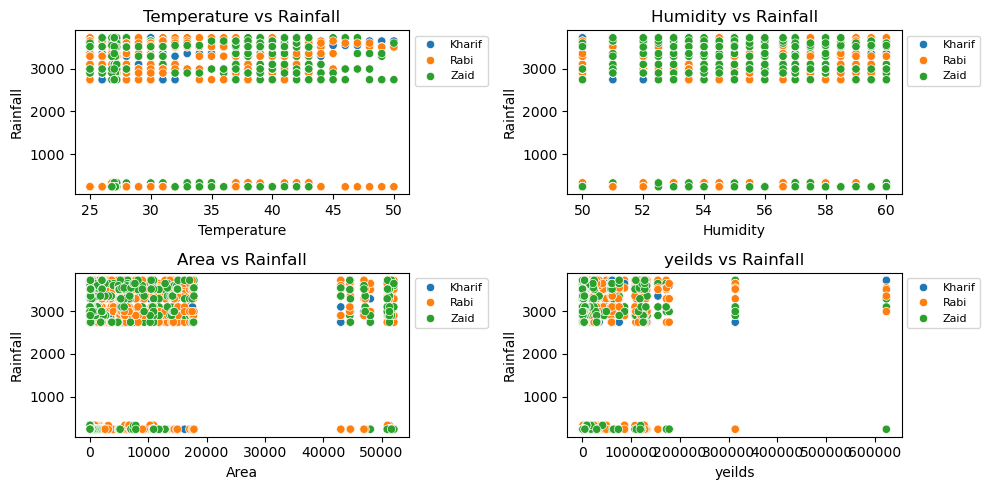

In [47]:
columns=['Temperature','Humidity','Area','yeilds']
fig,axs=plt.subplots(2,2,figsize=(10,5))
axs=axs.ravel()
for i , col in enumerate(columns):
    data=df_new.groupby(col)['Rainfall'].mean().reset_index()
    sns.scatterplot(x=col,y='Rainfall',hue='Season',data=df_new,ax=axs[i])
    axs[i].set_title(f'{col} vs Rainfall')
    axs[i].legend(bbox_to_anchor=(1,1),loc='upper left',fontsize=8)
plt.tight_layout()
plt.show()

In [48]:
averaged=df_new.groupby('Location')['Rainfall']

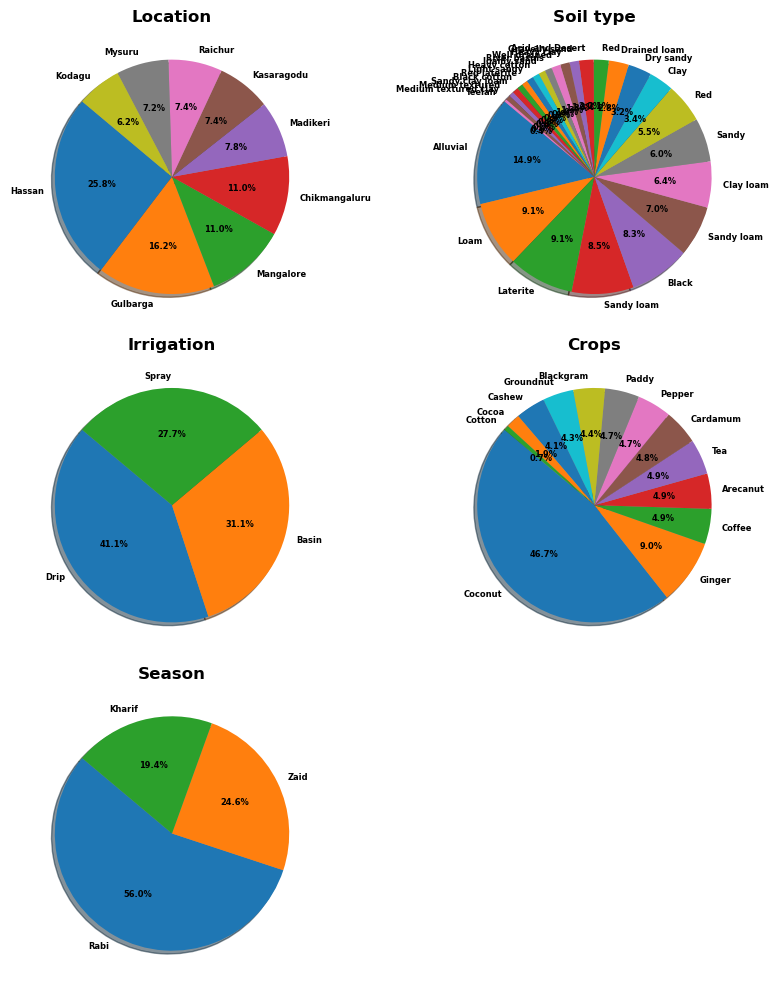

In [49]:
fig, axs = plt.subplots(3,2,figsize=(8,10))
axs=axs.ravel()
for i, col in enumerate(categorical_columns):
    values=df_new[col].value_counts().values
    labels=df_new[col].value_counts().index
    ax=axs[i]
    ax.pie(values, labels=labels,textprops={'fontsize': 6, 'fontweight': 'bold'},shadow=True,startangle=140,autopct='%1.1f%%')
    ax.set_title(col,fontweight='bold')

axs[-1].remove()
plt.tight_layout()
plt.show()

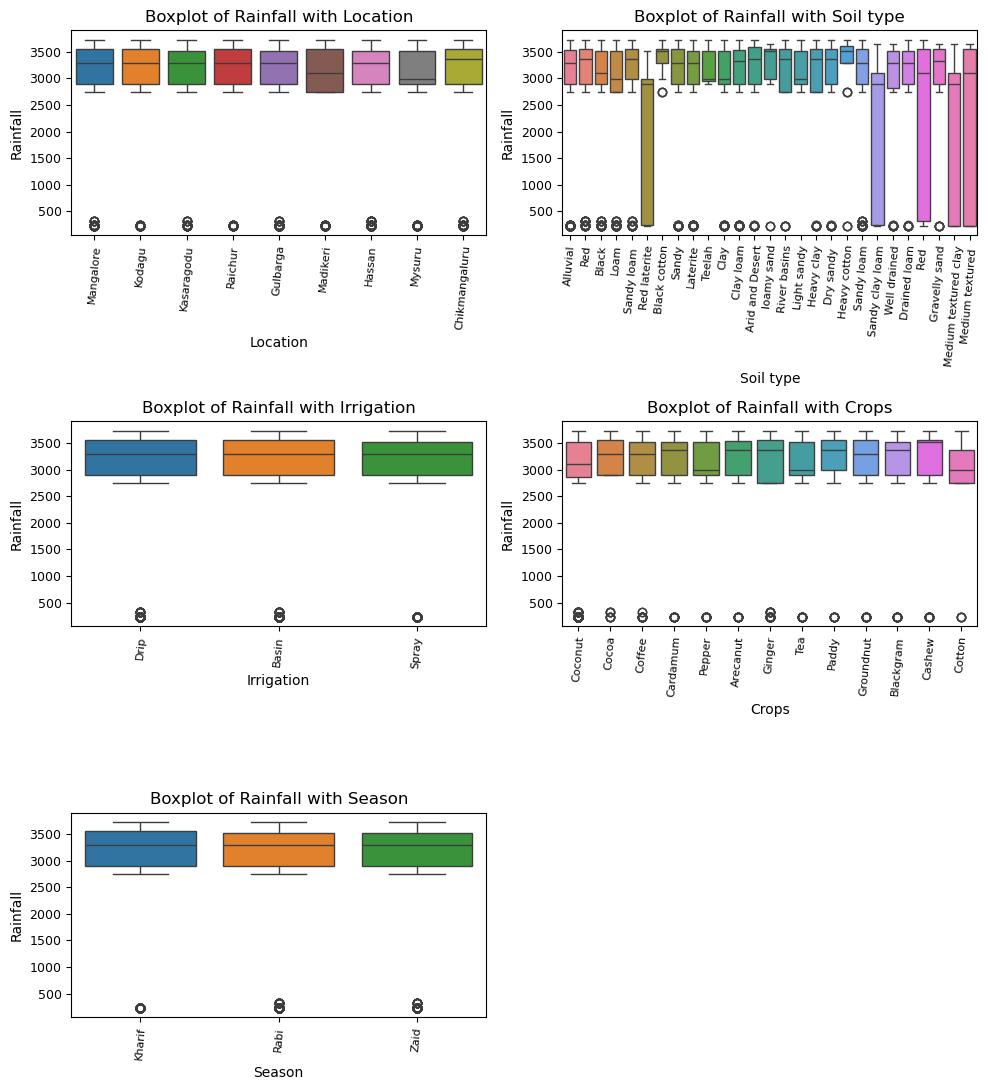

In [50]:
fig,axs=plt.subplots(3,2,figsize=(10,11))
axs = axs.ravel()

for ax,col in zip(axs,categorical_columns):
    sns.boxplot(x=col,y='Rainfall' ,hue=col ,ax=ax,data=df_new)
    ax.set_title(f"Boxplot of Rainfall with {col}")
    ax.tick_params(axis='x',labelsize=8,rotation=85)
    ax.tick_params(axis='y',labelsize=9)
axs[-1].remove()
plt.tight_layout()
plt.show()


### Normalization of Low Rainfall Outliers in Dataset:
- Rainfall values below 500 mm, considered unrealistic based on historical data (2004–2019), were adjusted by multiplying them by 10 to ensure consistency and improve the accuracy of statistical analyses

In [51]:
df_new.loc[df_new['Rainfall']<500,'Rainfall']*=10


<Axes: xlabel='Rainfall', ylabel='Count'>

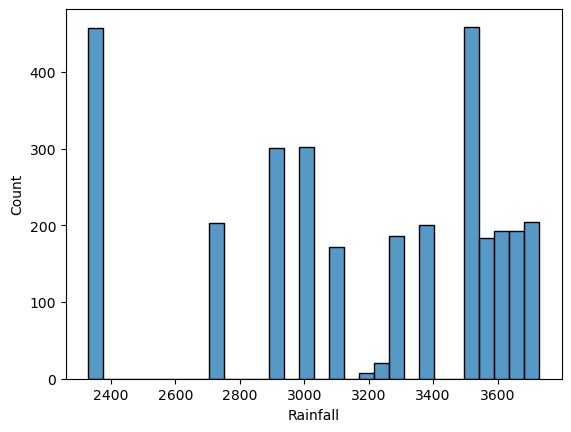

In [53]:
sns.histplot(x='Rainfall',bins=30,data=df_new)

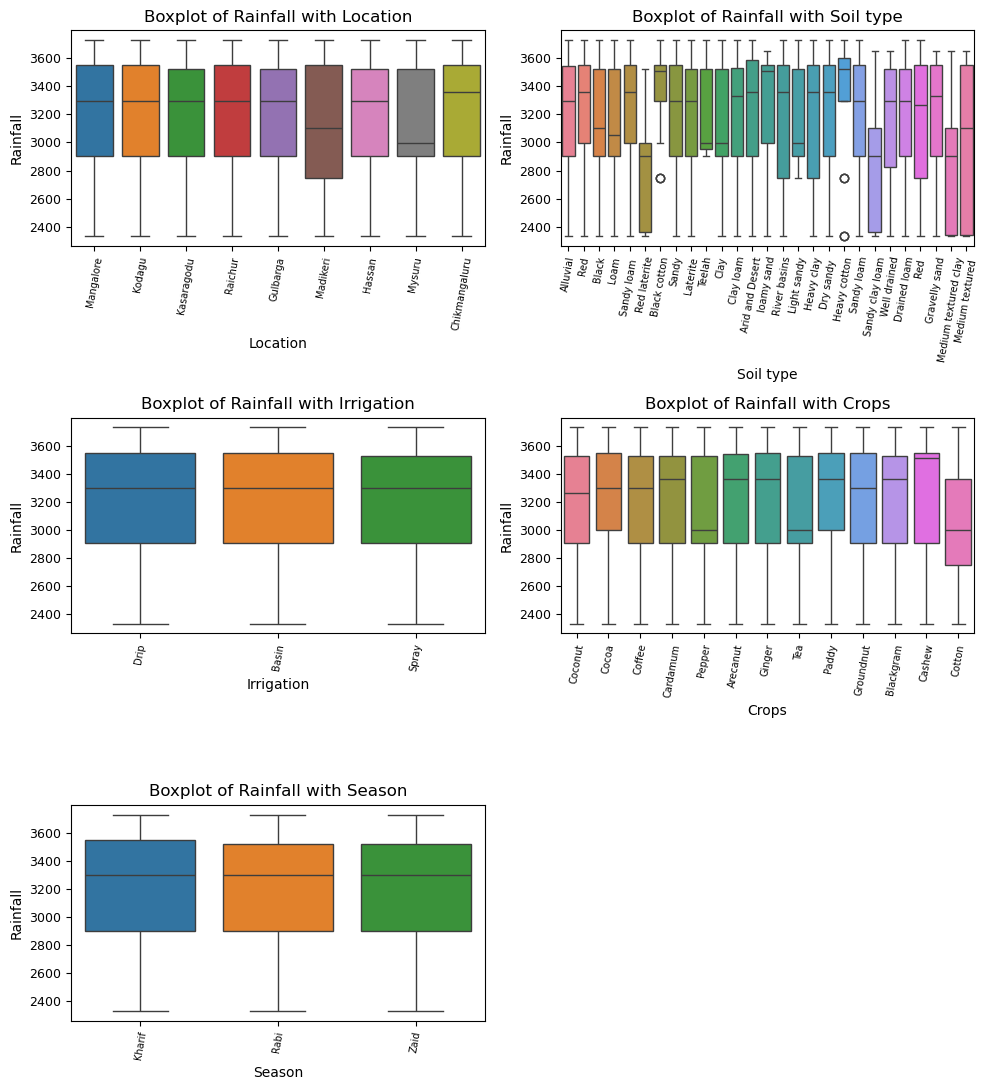

In [59]:
fig,axs=plt.subplots(3,2,figsize=(10,11))
axs = axs.ravel()

for ax,col in zip(axs,categorical_columns):
    sns.boxplot(x=col,y='Rainfall' ,hue=col ,ax=ax,data=df_new)
    ax.set_title(f"Boxplot of Rainfall with {col}")
    ax.tick_params(axis='x',labelsize=7,rotation=80)
    ax.tick_params(axis='y',labelsize=9)
if len(categorical_columns) < len(axs):
    for i in range(len(categorical_columns), len(axs)):
        fig.delaxes(axs[i])  # More robust than .remove()

plt.tight_layout()
plt.show()

### Key Insights:
**Soil type has the strongest influence on rainfall variation, While location, irrigation, season and crops show smaller differences.**  
<br><br>

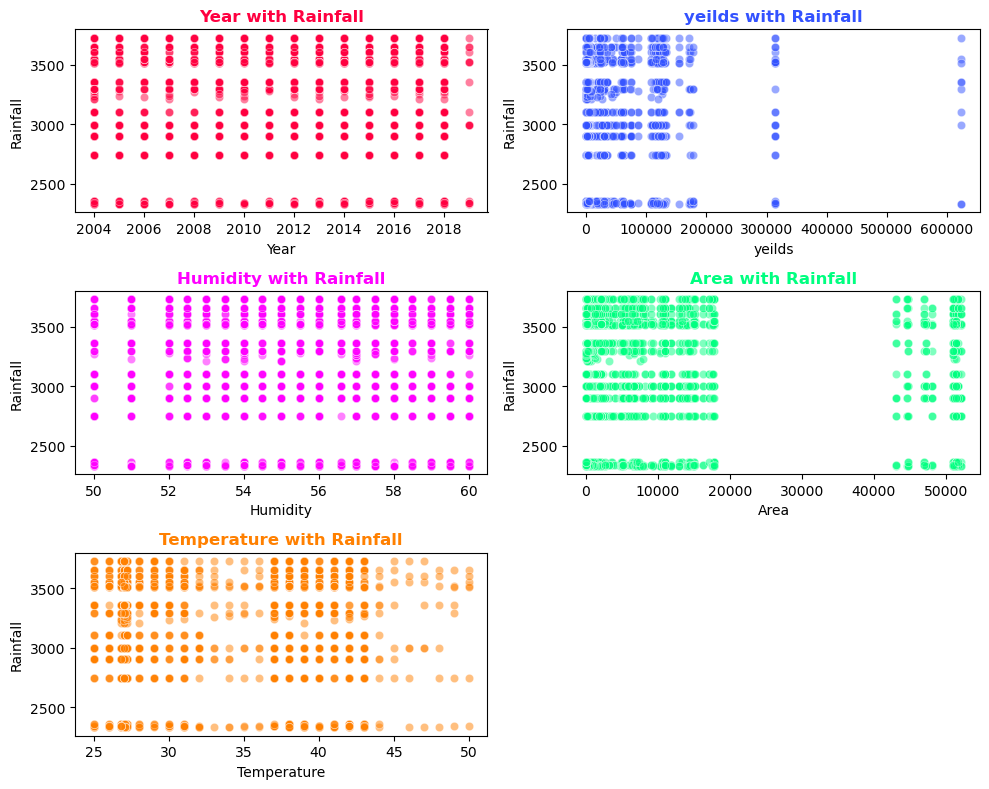

In [63]:
plots=[('Year','Rainfall','#ff0040'),
      ('yeilds','Rainfall','#3352ff'),
      ('Humidity','Rainfall','#ff00ff'),
      ('Area','Rainfall','#00ff80'),
       ('Temperature','Rainfall','#ff8000')]
fig,axs=plt.subplots(3,2,figsize=(10,8))
axs=axs.ravel()
for i,(x,y,color) in enumerate(plots):
    sns.scatterplot(x=x,y=y,data=df_new,ax=axs[i],marker='o',alpha=0.5,color=color)
    axs[i].set_title(f"{x} with Rainfall",color=color,fontweight='bold')

axs[-1].remove()
plt.tight_layout()
plt.show()